# VG-DeepLab — cross-dataset test on CADICA + explainability (no training)

This notebook **does not train anything**. It loads the 5 baseline models and the 5 VG-DeepLab models from your first run and answers two questions:

**Part A - cross-dataset (Objective 3).** The ARCADE-trained ensembles are applied *unchanged* to CADICA (another hospital, box labels only). Same box-level protocol as your earlier CADICA experiment (IoU ≥ 0.5, IoU ≥ 0.1, centre-hit; patient-level bootstrap). New here: baseline and VG-DeepLab are compared **on the same frames with a paired test**, so we can say whether the vessel supervision makes the model more (or less) robust to the new hospital. Operating points are the ones frozen on ARCADE out-of-fold data in the first run; nothing is tuned on CADICA.

**Part B - explainability (Objective 2), measured on all 300 ARCADE test images.**
1. *Built-in explanation:* VG-DeepLab predicts a **vessel map**. We measure whether lesions lie on it and whether false positives are "off-vessel".
2. *Counterfactual test:* we blank / swap the vessel map that the refinement head receives and measure how much the output changes. This shows how much the model really uses it.
3. *Seg-Grad-CAM* for the ensemble: localisation (pointing game, energy lift) with confidence intervals, deletion test (faithfulness), weight-randomisation test (sanity).

**No result is promised.** If the new model is not more robust, or the explanations fail a test, the notebook says so.

## How to run (Kaggle)
1. **Add Input** (right panel):
   * the **ARCADE dataset** (`nirmalgaud/arcade-dataset`),
   * the **output of your first notebook** "ARCADE Stenosis — VG-DeepLab" (Add Input → *Your Work* / *Notebooks*). It contains the 10 checkpoints.
2. Session options: **Accelerator = GPU T4**, **Internet = On** (CADICA is downloaded from Mendeley Data, about 5-10 minutes).
3. **Save Version → Save & Run All (Commit)**. Expected time: roughly 1.5-2 h.
4. Download `results_cadica_explain.zip` from the Output tab and send it to Claude, together with the figures SS-C6, SS-E1, SS-E4, SS-E5 if you can.

If CADICA cannot be downloaded, the notebook does **not** crash: it finishes the ARCADE parts and tells you what to do.

In [1]:
# Do NOT let pip touch torch: --no-deps keeps the preinstalled torch/numpy/opencv exactly as they are.
!pip install -q --no-deps segmentation-models-pytorch
print("Installs complete.")

Installs complete.


In [2]:
import os, sys, json, math, copy, random, shutil, time, warnings, subprocess, zipfile, re, traceback
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import requests

import torch, torch.nn as nn, torch.nn.functional as F
from torch.amp import autocast
for _try in range(8):          # smp needs a few small packages; install any that are missing WITHOUT touching torch
    try:
        import segmentation_models_pytorch as smp; break
    except ModuleNotFoundError as e:
        print("missing package:", e.name, "-> installing (no deps)")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", e.name.split(".")[0].replace("_", "-")])
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_CUDA = DEVICE.type == "cuda"
ON_KAGGLE = Path("/kaggle/working").exists()
BASE = Path("/kaggle/working") if ON_KAGGLE else (Path("/content") if Path("/content").exists() else Path.cwd())
SCRATCH = Path(os.environ.get("VG_SCRATCH", "/tmp/cadica_work")); SCRATCH.mkdir(parents=True, exist_ok=True)     # temporary files (not saved as notebook output)
print("Platform:", "Kaggle" if ON_KAGGLE else ("Colab" if Path("/content").exists() else "local"), "| work dir:", BASE, "| free disk for the download: %.0f GB" % (shutil.disk_usage(SCRATCH).free / 1e9))
print("Torch", torch.__version__, "| smp", smp.__version__, "|", torch.cuda.get_device_name(0) if USE_CUDA else "NO GPU (enable a GPU in the notebook settings!)")

Platform: Kaggle | work dir: /kaggle/working | free disk for the download: 1038 GB
Torch 2.11.0+cu130 | smp 0.6.0 | Tesla T4


In [3]:
# ============================================================
# CONFIG
# ============================================================
SMOKE_TEST = False         # False = the real run. True = 10-minute plumbing check (few images; numbers mean nothing).
IMG_SIZE, STENOSIS_CATEGORY_ID = 512, 26
N_FOLDS = 5                # fold models per ensemble (from the first run)

RUN_CADICA = True          # False = only the ARCADE parts
CADICA_SRC = None          # None = look in /kaggle/input, otherwise download from Mendeley Data; or a path to a .zip / an extracted folder
CADICA_DIRECT_URL = None   # optional: a direct zip link if the automatic download fails
MAX_FRAMES_PER_VIDEO = 6   # evenly spaced frames per CADICA video - the same sampling as your earlier CADICA experiment

# Operating points frozen on ARCADE out-of-fold data in the first run ('balanced-DEPLOY', file frozen_choices_v3.json). Nothing is tuned here.
FROZEN_OPS = {"B": dict(thr=0.40, min_area=150, tau=0.5, rel=0.75, max_k=99),      # B = baseline DeepLabV3+ R101 (5-fold ensemble)
              "N": dict(thr=0.35, min_area=150, tau=0.2, rel=0.75, max_k=3)}       # N = VG-DeepLab (5-fold ensemble)
EXPECT_DICE = {"B": 0.6197, "N": 0.6358}   # per-image Dice on ARCADE-test in the first run (used as a self-check of this notebook)

N_BOOT = 1000
N_LOC_CAD = 300                                  # CADICA true-positive detections used for the CAM localisation test (per model)
N_DEL = {"ARCADE-test": 120, "CADICA": 80}       # detections per kind (TP / FP) used for the deletion test
N_SANITY = 40                                    # detections per dataset for the weight-randomisation test
DEL_FRACS = [0.01, 0.02, 0.05, 0.10]
CAM_BATCH_NOTE = "CAM target = mean stenosis logit inside the predicted lesion; layer = DeepLabV3+ decoder output; averaged over the 5 fold models"

if SMOKE_TEST:
    N_FOLDS, N_BOOT, N_LOC_CAD, N_SANITY, MAX_FRAMES_PER_VIDEO = 2, 100, 12, 4, 2
    N_DEL = {"ARCADE-test": 5, "CADICA": 5}; SMOKE_ARC_N, SMOKE_CAD_PATIENTS = 40, 6

OUT_DIR = BASE / ("outputs_cadica_explain_smoke" if SMOKE_TEST else "outputs_cadica_explain"); OUT_DIR.mkdir(parents=True, exist_ok=True)
ERRORS = []
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
print(f"SMOKE_TEST={SMOKE_TEST} | folds per ensemble={N_FOLDS} | CADICA frames per video={MAX_FRAMES_PER_VIDEO} | bootstrap={N_BOOT}")

SMOKE_TEST=False | folds per ensemble=5 | CADICA frames per video=6 | bootstrap=1000


## Data: ARCADE test set (masks + boxes) and CADICA (boxes)

In [4]:
def find_arcade_root():
    for root in [Path("/kaggle/input"), Path.home() / ".cache" / "kagglehub"]:
        if root.exists():
            c = [p for p in root.rglob("test.json") if "stenosis" in str(p.parent.parent.parent.name).lower()]
            if c: return c[0].parent.parent.parent
    return None

DATASET_ROOT = find_arcade_root()
if DATASET_ROOT is None:
    try:
        import kagglehub
        dl = Path(kagglehub.dataset_download("nirmalgaud/arcade-dataset")); c = [p for p in dl.rglob("test.json") if "stenosis" in str(p).lower()]; DATASET_ROOT = c[0].parent.parent.parent
    except Exception as e:
        raise RuntimeError("ARCADE is not attached. On Kaggle: right panel -> Add Input -> search 'arcade-dataset' (nirmalgaud) -> Add, then run again.") from e
assert (DATASET_ROOT / "test" / "annotations" / "test.json").exists() and (DATASET_ROOT / "test" / "images").exists()
print("ARCADE root:", DATASET_ROOT)

def polys_to_mask(segs, h, w):
    full = np.zeros((h, w), np.uint8)
    for poly in segs or []:
        if isinstance(poly, list) and len(poly) >= 6:
            cv2.fillPoly(full, [np.round(np.array(poly, np.float32).reshape(-1, 2)).astype(np.int32)], 1)
    return full

def load_arcade(split, limit=None):
    """Gray 512x512 images, union mask, one box per lesion (bounding box of its polygon), one mask per lesion."""
    coco = json.load(open(DATASET_ROOT / split / "annotations" / f"{split}.json")); anns = {}
    for a in coco["annotations"]:
        if a["category_id"] == STENOSIS_CATEGORY_ID: anns.setdefault(a["image_id"], []).append(a)
    ims = sorted(coco["images"], key=lambda d: d["id"])
    if limit: ims = ims[:limit]
    imgs, masks, boxes, labels, names, lmasks = [], [], [], [], [], []
    for im in tqdm(ims, mininterval=20, desc=f"ARCADE {split}"):
        g = cv2.imread(str(DATASET_ROOT / split / "images" / im["file_name"]), cv2.IMREAD_GRAYSCALE); h, w = g.shape
        assert (h, w) == (IMG_SIZE, IMG_SIZE), f"{im['file_name']} is {g.shape}, expected {IMG_SIZE}x{IMG_SIZE}"
        union = np.zeros((h, w), np.uint8); bl, ml = [], []
        for a in anns.get(im["id"], []):
            m = polys_to_mask(a.get("segmentation"), h, w); ys, xs = np.nonzero(m)
            if len(ys) == 0: continue
            union |= m; bl.append((float(xs.min()), float(ys.min()), float(xs.max() + 1), float(ys.max() + 1))); ml.append(m.astype(bool))
        imgs.append(g); masks.append(union); boxes.append(bl); labels.append(["arcade"] * len(bl)); names.append(im["file_name"]); lmasks.append(ml)
    return dict(imgs=np.stack(imgs), masks=np.stack(masks), boxes=boxes, labels=labels, groups=list(range(len(imgs))), kinds=["lesion"] * len(imgs), names=names, lmasks=lmasks)

ARC_TEST = load_arcade("test", SMOKE_ARC_N if SMOKE_TEST else None)
print(f"ARCADE test: {len(ARC_TEST['imgs'])} images | {sum(len(b) for b in ARC_TEST['boxes'])} lesions")

ARCADE root: /kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis


ARCADE test:   0%|          | 0/300 [00:00<?, ?it/s]

ARCADE test: 300 images | 386 lesions


In [5]:
# ============================================================
# CADICA: find (attached input) or download (Mendeley Data), extract, index.  selectedVideos/pX/vY/{input,groundtruth}
# Same indexing code as your earlier CADICA notebook. If anything fails, the notebook continues with ARCADE only.
# ============================================================
CADICA_ID, CADICA_VERSIONS = "p9bpx9ctcv", [5, 4, 3]
CADICA_DIR = SCRATCH / "cadica_extracted"
HDR = {"User-Agent": "Mozilla/5.0"}

def _stream(url, dest):
    with requests.get(url, stream=True, timeout=120, allow_redirects=True, headers=HDR) as r:
        r.raise_for_status(); total = int(r.headers.get("content-length", 0)) or None; done = 0; t0 = time.time(); nxt = 0
        with open(dest, "wb") as f:
            for c in r.iter_content(1 << 20):
                f.write(c); done += len(c)
                if time.time() - t0 > nxt: print(f"  downloaded {done / 1e6:.0f} MB" + (f" of {total / 1e6:.0f} MB" if total else ""), flush=True); nxt += 30
    print(f"  download finished: {done / 1e6:.0f} MB in {time.time() - t0:.0f}s")

def _extract_needed(zpath, out, depth=0):
    """Extract png/txt (skips nonselected*). Handles zips nested inside zips."""
    zpath, out, n_ok = Path(zpath), Path(out), 0
    with zipfile.ZipFile(zpath) as z:
        names = z.namelist(); print("  " * depth + f"{zpath.name}: {len(names)} entries, e.g. {names[:3]}")
        for n in names:
            low = n.replace("\\", "/").lower()
            if low.endswith("/"): continue
            if low.endswith(".zip"):
                inner = out / "_nested" / f"{depth}_{Path(low).name}"; inner.parent.mkdir(parents=True, exist_ok=True)
                with z.open(n) as s, open(inner, "wb") as d: shutil.copyfileobj(s, d)
                n_ok += _extract_needed(inner, out, depth + 1); inner.unlink(missing_ok=True); continue
            if low.endswith((".png", ".txt")) and "nonselected" not in low: z.extract(n, out); n_ok += 1
    return n_ok

def _download_via_files_api(ver, out):
    from concurrent.futures import ThreadPoolExecutor
    base = f"https://data.mendeley.com/public-api/datasets/{CADICA_ID}/files"; todo = []
    def walk(fid, prefix):
        r = requests.get(base, params={"folder_id": fid, "version": ver}, headers=HDR, timeout=60); r.raise_for_status()
        for it in r.json():
            cd = it.get("content_details") or {}; name = it.get("filename") or it.get("name") or it.get("id")
            if cd.get("download_url"):
                if "nonselected" in (prefix + "/" + name).lower(): continue
                todo.append((cd["download_url"], Path(out) / prefix.lstrip("/") / name))
            elif it.get("id"):
                if "nonselected" in name.lower(): continue
                walk(it["id"], prefix + "/" + name)
    walk("root", ""); print("files to download:", len(todo))
    def get(t):
        url, dst = t; dst.parent.mkdir(parents=True, exist_ok=True)
        for _ in range(3):
            try:
                with requests.get(url, headers=HDR, timeout=90) as r: r.raise_for_status(); dst.write_bytes(r.content); return True
            except Exception: pass
        return False
    with ThreadPoolExecutor(16) as ex: ok = list(ex.map(get, todo))
    print("downloaded", sum(ok), "/", len(ok))
    for zp in list(Path(out).rglob("*.zip")):
        if zipfile.is_zipfile(zp): _extract_needed(zp, out); zp.unlink(missing_ok=True)

def _find_sel(base):
    base = Path(base)
    if not base.exists(): return []
    return [p for p in base.rglob("*") if p.is_dir() and p.name.lower() == "selectedvideos"]

def download_cadica():
    CADICA_DIR.mkdir(parents=True, exist_ok=True)
    urls = ([CADICA_DIRECT_URL] if CADICA_DIRECT_URL else []) + [f"https://data.mendeley.com/public-api/zip/{CADICA_ID}/download/{v}" for v in CADICA_VERSIONS]
    for u in urls:
        try:
            print("Trying:", u); zp = SCRATCH / "cadica_download.zip"; _stream(u, zp)
            if zipfile.is_zipfile(zp):
                n = _extract_needed(zp, CADICA_DIR); print("  extracted files:", n); zp.unlink(missing_ok=True)
                if _find_sel(CADICA_DIR): return True
                print("  extracted, but no 'selectedVideos' folder inside")
            else: print("  not a zip file, trying the next source")
        except Exception as e: print("  failed:", repr(e)[:200])
    for v in CADICA_VERSIONS:
        try:
            print("Trying the Mendeley files API, version", v); _download_via_files_api(v, CADICA_DIR)
            if _find_sel(CADICA_DIR): return True
        except Exception as e: print("  failed:", repr(e)[:200])
    return False

def prepare_cadica(src=None):
    if src is not None:
        src = Path(src)
        if src.is_file() and src.suffix.lower() == ".zip": _extract_needed(src, CADICA_DIR)
        elif src.is_dir():
            f = _find_sel(src) or ([src] if src.name.lower() == "selectedvideos" else [])
            if f: return f[0]
    for root in [Path("/kaggle/input"), CADICA_DIR]:
        f = _find_sel(root)
        if f: return f[0]
    if Path("/kaggle/input").exists():                      # an attached but still zipped copy
        for z in Path("/kaggle/input").rglob("*.zip"):
            if "cadica" in z.name.lower() and zipfile.is_zipfile(z):
                _extract_needed(z, CADICA_DIR)
                if _find_sel(CADICA_DIR): return _find_sel(CADICA_DIR)[0]
    if not download_cadica(): raise RuntimeError("automatic CADICA download failed")
    return _find_sel(CADICA_DIR)[0]

def parse_gt_file(p):
    boxes = []
    for line in Path(p).read_text().splitlines():
        toks = [t for t in re.split(r"[,\s\[\]]+", line.strip()) if t]
        if len(toks) < 4: continue
        try: x, y, w, h = [float(t) for t in toks[:4]]
        except ValueError: continue
        boxes.append((x, y, x + w, y + h, "_".join(toks[4:]) if len(toks) > 4 else "unknown"))
    return boxes

def frame_no(path):
    d = re.findall(r"\d+", Path(path).stem); return int(d[-1]) if d else None

def index_cadica(root, max_per_video):
    recs = []
    for pdir in sorted((p for p in root.glob("p*") if p.is_dir()), key=lambda p: (len(p.name), p.name)):
        for vdir in sorted((v for v in pdir.glob("v*") if v.is_dir()), key=lambda p: (len(p.name), p.name)):
            inp = vdir / "input"
            if not inp.is_dir(): continue
            frames = {frame_no(f): f for f in inp.glob("*.png") if frame_no(f) is not None}
            gt_dir = vdir / "groundtruth"; gts = sorted(gt_dir.glob("*.txt")) if gt_dir.is_dir() else []; chosen = []
            if gts:
                kind = "lesion"
                for g in gts:
                    n = frame_no(g); b = parse_gt_file(g)
                    if n in frames and b: chosen.append((frames[n], b))
            else:
                kind = "normal"; nums = []
                for sf in vdir.glob("*electedFrames*.txt"):
                    for line in sf.read_text().splitlines():
                        d = re.findall(r"\d+", line)
                        if d: nums.append(int(d[-1]))
                chosen = [(frames[n], []) for n in sorted(set(nums)) if n in frames]
            if not chosen: continue
            if max_per_video and len(chosen) > max_per_video:
                idx = np.unique(np.linspace(0, len(chosen) - 1, max_per_video).round().astype(int)); chosen = [chosen[i] for i in idx]
            for fpath, b in chosen: recs.append(dict(path=fpath, patient=pdir.name, video=f"{pdir.name}/{vdir.name}", kind=kind, boxes=b))
    return recs

def sev_bin(label):
    m = re.search(r"(\d+)", str(label))
    if not m: return "unknown"
    lo = int(m.group(1)); return "<50" if lo < 50 else "50-69" if lo < 70 else "70-89" if lo < 90 else ">=90"

CAD, HAVE_CAD = None, False
if RUN_CADICA:
    try:
        CAD_ROOT = prepare_cadica(os.environ.get("VG_CADICA_SRC", CADICA_SRC)); print("CADICA root:", CAD_ROOT)
        recs = index_cadica(CAD_ROOT, MAX_FRAMES_PER_VIDEO)
        if SMOKE_TEST:
            keep = sorted({r["patient"] for r in recs}, key=lambda p: (len(p), p))[:SMOKE_CAD_PATIENTS]; recs = [r for r in recs if r["patient"] in keep]
        assert len(recs) > 0, "no CADICA frames indexed"
        imgs, boxes, labels, groups, kinds, names = [], [], [], [], [], []
        for r in tqdm(recs, mininterval=20, desc="Loading CADICA frames"):
            g = cv2.imread(str(r["path"]), cv2.IMREAD_GRAYSCALE); h, w = g.shape; sx, sy = IMG_SIZE / w, IMG_SIZE / h
            imgs.append(g if (h, w) == (IMG_SIZE, IMG_SIZE) else cv2.resize(g, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
            boxes.append([(b[0] * sx, b[1] * sy, b[2] * sx, b[3] * sy) for b in r["boxes"]]); labels.append([b[4] for b in r["boxes"]])
            groups.append(r["patient"]); kinds.append(r["kind"]); names.append(str(r["path"]))
        CAD = dict(imgs=np.stack(imgs), masks=None, boxes=boxes, labels=labels, groups=groups, kinds=kinds, names=names, lmasks=None); HAVE_CAD = True
        kc = Counter(kinds)
        print("\n=== SS-C1: CADICA indexing summary (earlier experiment: 42 patients, 382 videos, 1538 lesion frames, 673 normal frames, 2344 boxes) ===")
        print(f"patients: {len(set(groups))} | videos: {len(set(r['video'] for r in recs))} | lesion frames: {kc['lesion']} | normal frames: {kc['normal']} | lesion boxes: {sum(len(b) for b in boxes)}")
        print("severity bins:", dict(Counter(sev_bin(l) for ls in labels for l in ls)))
    except Exception as e:
        traceback.print_exc(); ERRORS.append("CADICA data")
        print("\n" + "!" * 100 + "\nCADICA IS NOT AVAILABLE -> the notebook continues with the ARCADE parts only.\nFix: open https://data.mendeley.com/datasets/p9bpx9ctcv/5 , download the zip to your computer, upload it to Kaggle as a (private) dataset,"
              "\nattach it with Add Input and run this notebook again (the zip or the extracted folder is found automatically).\n" + "!" * 100)
DATASETS = {"ARCADE-test": ARC_TEST}
if HAVE_CAD: DATASETS["CADICA"] = CAD

Trying: https://data.mendeley.com/public-api/zip/p9bpx9ctcv/download/5
  downloaded 1 MB of 3072 MB
  downloaded 1005 MB of 3072 MB
  downloaded 1806 MB of 3072 MB
  downloaded 2765 MB of 3072 MB
  download finished: 3072 MB in 99s
cadica_download.zip: 1 entries, e.g. ['CADICA a new dataset for coronary artery disease/CADICA.zip']
  0_cadica.zip: 37926 entries, e.g. ['CADICA/', 'CADICA/metadata.xlsx', 'CADICA/nonselectedVideos/']
  extracted files: 22617
CADICA root: /tmp/cadica_work/cadica_extracted/CADICA/selectedVideos


Loading CADICA frames:   0%|          | 0/2211 [00:00<?, ?it/s]


=== SS-C1: CADICA indexing summary (earlier experiment: 42 patients, 382 videos, 1538 lesion frames, 673 normal frames, 2344 boxes) ===
patients: 42 | videos: 382 | lesion frames: 1538 | normal frames: 673 | lesion boxes: 2344
severity bins: {'<50': 1126, '>=90': 472, '70-89': 372, '50-69': 374}


## Models: the two 5-fold ensembles from the first run (loaded, not trained)
`B` = plain DeepLabV3+ R101, `N` = VG-DeepLab (vessel head + vessel-guided refinement). Inference uses the same test-time augmentation as the first run (2 scales x flip), then the frozen operating point.

In [6]:
class VGNet(nn.Module):
    """Identical to the class in the training notebook. forward -> (stenosis logit, coarse stenosis logit, vessel logit or None)."""
    def __init__(self, encoder_weights=None, aux=True, refine=True):
        super().__init__()
        self.aux, self.refine = aux, refine
        self.net = smp.DeepLabV3Plus(encoder_name="resnet101", encoder_weights=encoder_weights, in_channels=3, classes=2 if aux else 1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        if refine:
            cin = 3 if aux else 2
            self.ref = nn.Sequential(nn.Conv2d(cin, 24, 3, padding=1), nn.ReLU(inplace=True),
                                     nn.Conv2d(24, 24, 3, padding=2, dilation=2), nn.ReLU(inplace=True),
                                     nn.Conv2d(24, 24, 3, padding=4, dilation=4), nn.ReLU(inplace=True),
                                     nn.Conv2d(24, 24, 3, padding=1), nn.ReLU(inplace=True), nn.Conv2d(24, 1, 1))
    def parts(self, x, detach=True, vessel_override=None):
        """Returns (final logit, coarse logit, vessel logit). detach=False lets gradients flow through the refinement inputs (used by Grad-CAM only).
        vessel_override: a vessel PROBABILITY map given to the refinement head instead of the model's own (counterfactual test)."""
        out = self.net((x - self.mean) / self.std); s = out[:, :1]; v = out[:, 1:2] if self.aux else None
        if not self.refine: return s, s, v
        d = (lambda t: t.detach()) if detach else (lambda t: t)
        f = [x[:, :1] * 2 - 1, torch.sigmoid(d(s)) * 2 - 1]
        if self.aux: f.append((torch.sigmoid(d(v)) if vessel_override is None else vessel_override) * 2 - 1)
        return s + self.ref(torch.cat(f, 1)), s, v
    def forward(self, x): return self.parts(x)

INPUT_CKPTS = {}
for _root in [BASE / "run", Path("/kaggle/input"), Path(os.environ.get("VG_CKPT_DIR", "/nonexistent"))]:
    if _root.exists():
        for _p in sorted(_root.rglob("*_f[0-9].pt")):
            if "smoke" not in str(_p).lower(): INPUT_CKPTS.setdefault(_p.name, _p)
SPECS = {"B": ("dl3_r101", False, False), "N": ("vg_dl3", True, True)}
NAMES = {"B": "B baseline DeepLabV3+", "N": "N VG-DeepLab"}
missing = [f"{t}_f{f}.pt" for t, _, _ in SPECS.values() for f in range(N_FOLDS) if f"{t}_f{f}.pt" not in INPUT_CKPTS]
if missing: raise FileNotFoundError(f"Checkpoints not found: {missing}. On Kaggle: Add Input -> Your Work / Notebooks -> 'ARCADE Stenosis — VG-DeepLab' (the output of your first run), then run again.")
MODELS = {}
for k, (tag, aux, refine) in SPECS.items():
    MODELS[k] = []
    for f in range(N_FOLDS):
        m = VGNet(None, aux, refine); m.load_state_dict(torch.load(INPUT_CKPTS[f"{tag}_f{f}.pt"], map_location="cpu")); MODELS[k].append(m.to(DEVICE).eval())
    print(f"{NAMES[k]}: {N_FOLDS} fold models loaded from {INPUT_CKPTS[f'{tag}_f0.pt'].parent}")

# frozen operating points: if the json of the first run is attached, it must agree with the values in the config cell
for _root in [Path("/kaggle/input"), Path(os.environ.get("VG_CKPT_DIR", "/nonexistent")).parent]:
    if _root.exists():
        for _p in _root.rglob("frozen_choices_v3.json"):
            if "smoke" in str(_p).lower(): continue
            fz = json.load(open(_p)); hd = fz.get("headline", "balanced-DEPLOY")
            for key, op in fz["ops"].items():
                if key[0] in FROZEN_OPS:
                    new = {q: op[hd][q] for q in ["thr", "min_area", "tau", "rel", "max_k"]}
                    if any(abs(float(new[q]) - float(FROZEN_OPS[key[0]][q])) > 1e-9 for q in new): print(f"NOTE: operating point of {key[0]} taken from {_p.name}: {new} (differs from the config cell)")
                    FROZEN_OPS[key[0]] = new
            break
print("operating points used (frozen on ARCADE out-of-fold data, never tuned on CADICA or on the test set):"); [print("  ", NAMES[k], FROZEN_OPS[k]) for k in FROZEN_OPS]

@torch.no_grad()
def ens_predict(models, imgs, tta=True, bs=8, desc=None):
    """Mean stenosis probability of the fold models (N,H,W) float16 and mean vessel probability uint8 (or None).
    tta=True: 2 scales (1.0, 1.25) x horizontal flip, exactly as in the first run."""
    S, V = [], []; has_v = models[0].aux
    for st in tqdm(range(0, len(imgs), bs), mininterval=20, desc=desc, disable=desc is None):
        x = torch.from_numpy(np.stack(imgs[st:st + bs])).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(DEVICE); acc_s, acc_v, n = 0.0, 0.0, 0
        for m in models:
            for sc in ((1.0, 1.25) if tta else (1.0,)):
                xs = x if sc == 1.0 else F.interpolate(x, scale_factor=sc, mode="bilinear", align_corners=False)
                for flip in ((False, True) if tta else (False,)):
                    xi = torch.flip(xs, dims=[3]) if flip else xs
                    with autocast("cuda", enabled=USE_CUDA): s2, _, v = m(xi)
                    outs = [torch.sigmoid(s2.float())] + ([torch.sigmoid(v.float())] if has_v else [])
                    if flip: outs = [torch.flip(o, dims=[3]) for o in outs]
                    if sc != 1.0: outs = [F.interpolate(o, size=x.shape[-2:], mode="bilinear", align_corners=False) for o in outs]
                    acc_s = acc_s + outs[0]; n += 1
                    if has_v: acc_v = acc_v + outs[1]
        S.append((acc_s / n)[:, 0].cpu().numpy().astype(np.float16))
        if has_v: V.append((acc_v / n)[:, 0].mul(255).round().clamp(0, 255).byte().cpu().numpy())
    return np.concatenate(S), (np.concatenate(V) if V else None)

def extract_instances(prob, op):
    """Lesions = connected blobs of (prob > thr) with area >= min_area, score = mean probability; then the frozen keep-rule (tau, rel, max_k). Same logic as the first notebook."""
    p = prob.astype(np.float32); n, lab, stats, _ = cv2.connectedComponentsWithStats((p > op["thr"]).astype(np.uint8), connectivity=8); out = []
    for i in range(1, n):
        x, y, w, h, a = stats[i]
        if a < op["min_area"]: continue
        crop = lab[y:y + h, x:x + w] == i; pv = p[y:y + h, x:x + w][crop]
        out.append(dict(box=(int(x), int(y), int(x + w), int(y + h)), area=int(a), score=float(pv.mean()), maxp=float(pv.max()), crop=crop))
    out.sort(key=lambda d: -d["score"])
    return [d for d in out if d["score"] >= op["tau"] and d["score"] >= op["rel"] * out[0]["score"]][:int(op["max_k"])]

def full_mask(ins):
    reg = np.zeros((IMG_SIZE, IMG_SIZE), bool); x0, y0, x1, y1 = ins["box"]; reg[y0:y1, x0:x1] = ins["crop"]; return reg
def paint(insts):
    reg = np.zeros((IMG_SIZE, IMG_SIZE), bool)
    for i in insts: x0, y0, x1, y1 = i["box"]; reg[y0:y1, x0:x1] |= i["crop"]
    return reg
def dice_img(pr, gt):
    a, b, c = np.count_nonzero(pr & gt), np.count_nonzero(pr & ~gt), np.count_nonzero(~pr & gt); return 1.0 if a + b + c == 0 else 2 * a / (2 * a + b + c)

t0 = time.time(); PROB, VES, INST = {}, {}, {}
for dn, D in DATASETS.items():
    for k in SPECS:
        PROB[(k, dn)], v = ens_predict(MODELS[k], D["imgs"], desc=f"{k} on {dn}")
        if v is not None: VES[dn] = v
        INST[(k, dn)] = [extract_instances(p, FROZEN_OPS[k]) for p in PROB[(k, dn)]]
print(f"inference finished in {(time.time() - t0) / 60:.1f} min")
DICE_ARC = {k: np.array([dice_img(paint(ins), mk > 0) for ins, mk in zip(INST[(k, "ARCADE-test")], ARC_TEST["masks"])]) for k in SPECS}
print("\n=== SS-C0: self-check on ARCADE-test (per-image Dice must reproduce the first run) ===")
for k in SPECS:
    ok = abs(DICE_ARC[k].mean() - EXPECT_DICE[k]) < 0.003
    print(f"  {NAMES[k]}: Dice/img {DICE_ARC[k].mean():.4f} | first run {EXPECT_DICE[k]:.4f} ->", "OK" if ok else ("(smoke test: not comparable)" if SMOKE_TEST else "MISMATCH - tell Claude before using any number below"))

B baseline DeepLabV3+: 5 fold models loaded from /kaggle/input/notebooks/fahimmuntasir1168/arcade-stenosis-vg-deeplab/run
N VG-DeepLab: 5 fold models loaded from /kaggle/input/notebooks/fahimmuntasir1168/arcade-stenosis-vg-deeplab/run
operating points used (frozen on ARCADE out-of-fold data, never tuned on CADICA or on the test set):
   B baseline DeepLabV3+ {'thr': 0.4, 'min_area': 150, 'tau': 0.5, 'rel': 0.75, 'max_k': 99}
   N VG-DeepLab {'thr': 0.35, 'min_area': 150, 'tau': 0.2, 'rel': 0.75, 'max_k': 3}


B on ARCADE-test:   0%|          | 0/38 [00:00<?, ?it/s]

N on ARCADE-test:   0%|          | 0/38 [00:00<?, ?it/s]

B on CADICA:   0%|          | 0/277 [00:00<?, ?it/s]

N on CADICA:   0%|          | 0/277 [00:00<?, ?it/s]

inference finished in 35.9 min

=== SS-C0: self-check on ARCADE-test (per-image Dice must reproduce the first run) ===
  B baseline DeepLabV3+: Dice/img 0.6197 | first run 0.6197 -> OK
  N VG-DeepLab: Dice/img 0.6358 | first run 0.6358 -> OK


# PART A - cross-dataset test (ARCADE → CADICA, zero-shot)
Box-level evaluation with three matching rules: **IoU ≥ 0.5** (strict), **IoU ≥ 0.1** (lenient), **hit** (centre of the predicted box inside the GT box or the other way round). Predicted boxes are the bounding boxes of the predicted lesion masks. Confidence intervals: bootstrap over **patients** on CADICA (frames of one patient are not independent) and over images on ARCADE. Lesion-free CADICA frames are included, so false alarms on healthy frames are counted (frame specificity).

In [7]:
try:
    CRITS = ["i50", "i10", "hit"]
    def box_iou(a, b):
        ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
        inter = ix * iy; u = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
        return inter / u if u > 0 else 0.0
    def center_hit(p, g):
        pc = ((p[0] + p[2]) / 2, (p[1] + p[3]) / 2); gc = ((g[0] + g[2]) / 2, (g[1] + g[3]) / 2)
        return (g[0] <= pc[0] <= g[2] and g[1] <= pc[1] <= g[3]) or (p[0] <= gc[0] <= p[2] and p[1] <= gc[1] <= p[3])
    def match_frame(pboxes, gboxes, crit):
        used, tp, gt_hit = set(), [False] * len(pboxes), [False] * len(gboxes)
        for i, pb in enumerate(pboxes):                      # pboxes are sorted by score (descending)
            best, bj = -1.0, -1
            for j, gb in enumerate(gboxes):
                if j in used: continue
                iou = box_iou(pb, gb)
                if crit == "hit": ok, s = center_hit(pb, gb), 1.0 + iou
                else:             ok, s = iou >= (0.5 if crit == "i50" else 0.1), iou
                if ok and s > best: best, bj = s, j
            if bj >= 0: used.add(bj); tp[i] = True; gt_hit[bj] = True
        return tp, gt_hit
    def evaluate(insts, D):
        rows, grows = [], []
        for k, (ins, gb) in enumerate(zip(insts, D["boxes"])):
            pb = [i["box"] for i in ins]; row = dict(group=D["groups"][k], kind=D["kinds"][k], n_pred=len(pb), n_gt=len(gb)); flags = {}
            for c in CRITS:
                tp, gh = match_frame(pb, gb, c); flags[c] = gh
                row[f"tp_{c}"] = sum(tp); row[f"fp_{c}"] = len(pb) - sum(tp); row[f"fn_{c}"] = len(gb) - sum(gh)
            rows.append(row)
            for j in range(len(gb)): grows.append(dict(group=D["groups"][k], sev=sev_bin(D["labels"][k][j]), m_i50=flags["i50"][j], m_i10=flags["i10"][j], m_hit=flags["hit"][j]))
        return pd.DataFrame(rows), pd.DataFrame(grows)
    def prf(tp, fp, fn):
        p = tp / max(tp + fp, 1e-9); r = tp / max(tp + fn, 1e-9); return p, r, 2 * p * r / max(p + r, 1e-9)
    def group_sums(df, crit): return df.groupby("group", sort=True)[[f"tp_{crit}", f"fp_{crit}", f"fn_{crit}"]].sum().values
    def boot_f1(df, crit, seed=0):
        g = group_sums(df, crit); rng = np.random.default_rng(seed)
        return np.percentile([prf(*g[rng.integers(0, len(g), len(g))].sum(0))[2] for _ in range(N_BOOT)], [2.5, 97.5])
    def paired_f1(dfA, dfB, crit, seed=0):
        # F1(B) - F1(A) with a paired cluster bootstrap (the same patients / images are resampled for both models)
        A, B = group_sums(dfA, crit), group_sums(dfB, crit); rng = np.random.default_rng(seed); d = []
        for _ in range(N_BOOT):
            i = rng.integers(0, len(A), len(A)); d.append(prf(*B[i].sum(0))[2] - prf(*A[i].sum(0))[2])
        return prf(*B.sum(0))[2] - prf(*A.sum(0))[2], np.percentile(d, 2.5), np.percentile(d, 97.5), float((np.array(d) > 0).mean())
    def spec_counts(df):
        nor = df[df.kind == "normal"]
        if not len(nor): return None
        g = nor.assign(clean=(nor.n_pred == 0).astype(int)).groupby("group", sort=True).agg(clean=("clean", "sum"), n=("clean", "size")); return g.values
    def summarize(dfF):
        out = {}
        for c in CRITS:
            p, r, f = prf(dfF[f"tp_{c}"].sum(), dfF[f"fp_{c}"].sum(), dfF[f"fn_{c}"].sum()); lo, hi = boot_f1(dfF, c)
            out.update({f"P_{c}": p, f"R_{c}": r, f"F1_{c}": f, f"F1_{c}_lo": lo, f"F1_{c}_hi": hi})
        les, nor = dfF[dfF.kind == "lesion"], dfF[dfF.kind == "normal"]
        out["frame_sens"] = float((les.tp_hit > 0).mean()) if len(les) else np.nan; out["frame_spec"] = float((nor.n_pred == 0).mean()) if len(nor) else np.nan
        out["preds_per_frame"] = float(dfF.n_pred.mean()); return out
    def ci(lo, hi): return f"[{lo:.3f},{hi:.3f}]"

    RES, FR = {}, {}
    for (k, dn), insts in INST.items():
        dfF, dfG = evaluate(insts, DATASETS[dn]); RES[(k, dn)] = summarize(dfF); FR[(k, dn)] = (dfF, dfG)
    rows = []
    for dn in DATASETS:
        for k in SPECS:
            r = RES[(k, dn)]
            rows.append({"dataset": dn, "model": k, "P@.5": r["P_i50"], "R@.5": r["R_i50"], "F1@.5 [95% CI]": f"{r['F1_i50']:.3f} {ci(r['F1_i50_lo'], r['F1_i50_hi'])}",
                         "P@.1": r["P_i10"], "R@.1": r["R_i10"], "F1@.1 [95% CI]": f"{r['F1_i10']:.3f} {ci(r['F1_i10_lo'], r['F1_i10_hi'])}",
                         "F1 hit [95% CI]": f"{r['F1_hit']:.3f} {ci(r['F1_hit_lo'], r['F1_hit_hi'])}", "frame sens": r["frame_sens"], "frame spec": r["frame_spec"], "preds/frame": r["preds_per_frame"]})
    TAB_X = pd.DataFrame(rows)
    print("=== SS-C2: box-level results, B = baseline ensemble, N = VG-DeepLab ensemble (zero-shot on CADICA) ==="); print(TAB_X.round(3).to_string(index=False))
    TAB_X.to_csv(OUT_DIR / "partA_cross_dataset_table.csv", index=False)

    TAB_DROP = TAB_PAIRX = SEV = pd.DataFrame()
    if HAVE_CAD:
        rows = []
        for k in SPECS:
            for c in CRITS:
                a, b = RES[(k, "ARCADE-test")][f"F1_{c}"], RES[(k, "CADICA")][f"F1_{c}"]
                rows.append({"model": k, "criterion": {"i50": "IoU>=0.5", "i10": "IoU>=0.1", "hit": "centre-hit"}[c], "ARCADE-test F1": a, "CADICA F1": b, "abs drop": a - b, "rel drop %": 100 * (a - b) / max(a, 1e-9)})
        TAB_DROP = pd.DataFrame(rows)
        print("\n=== SS-C3: drop ARCADE -> CADICA (earlier single DeepLabV3+ model, other operating point: F1@0.1 0.703 -> 0.419, F1@0.5 0.281 -> 0.113) ==="); print(TAB_DROP.round(3).to_string(index=False))
    rows = []
    for dn in DATASETS:
        for c in CRITS:
            d, lo, hi, pg = paired_f1(FR[("B", dn)][0], FR[("N", dn)][0], c)
            rows.append({"dataset": dn, "metric": "F1 " + {"i50": "IoU>=0.5", "i10": "IoU>=0.1", "hit": "centre-hit"}[c], "B": RES[("B", dn)][f"F1_{c}"], "N": RES[("N", dn)][f"F1_{c}"],
                         "N minus B": d, "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "P(N better)": pg, "CI excludes 0": "YES" if (lo > 0 or hi < 0) else "no"})
        sa, sb = spec_counts(FR[("B", dn)][0]), spec_counts(FR[("N", dn)][0])
        if sa is not None:
            rng = np.random.default_rng(0); dd = []
            for _ in range(N_BOOT):
                i = rng.integers(0, len(sa), len(sa)); dd.append(sb[i, 0].sum() / max(sb[i, 1].sum(), 1) - sa[i, 0].sum() / max(sa[i, 1].sum(), 1))
            d = sb[:, 0].sum() / sb[:, 1].sum() - sa[:, 0].sum() / sa[:, 1].sum(); lo, hi = np.percentile(dd, [2.5, 97.5])
            rows.append({"dataset": dn, "metric": "frame specificity (healthy frames)", "B": RES[("B", dn)]["frame_spec"], "N": RES[("N", dn)]["frame_spec"], "N minus B": d, "95% CI": f"[{lo:+.3f}, {hi:+.3f}]",
                         "P(N better)": float((np.array(dd) > 0).mean()), "CI excludes 0": "YES" if (lo > 0 or hi < 0) else "no"})
    TAB_PAIRX = pd.DataFrame(rows)
    print("\n=== SS-C4: VG-DeepLab minus baseline, paired bootstrap (patients on CADICA, images on ARCADE) ==="); print(TAB_PAIRX.round(3).to_string(index=False))
    TAB_DROP.to_csv(OUT_DIR / "partA_drop.csv", index=False); TAB_PAIRX.to_csv(OUT_DIR / "partA_paired_N_vs_B.csv", index=False)
    if HAVE_CAD:
        rows = []
        for k in SPECS:
            g = FR[(k, "CADICA")][1]
            for sb_ in ["<50", "50-69", "70-89", ">=90"]:
                s = g[g.sev == sb_]
                if len(s): rows.append({"model": k, "severity %": sb_, "n_lesions": len(s), "recall@IoU0.1": s.m_i10.mean(), "recall@hit": s.m_hit.mean(), "recall@IoU0.5": s.m_i50.mean()})
        SEV = pd.DataFrame(rows); print("\n=== SS-C5: CADICA recall by lesion severity (share of GT lesions found) ==="); print(SEV.round(3).to_string(index=False)); SEV.to_csv(OUT_DIR / "partA_cadica_severity_recall.csv", index=False)
        wins = TAB_PAIRX[(TAB_PAIRX.dataset == "CADICA") & (TAB_PAIRX["CI excludes 0"] == "YES")]
        print("\n--- what the data supports (cross-dataset) ---")
        if len(wins[wins["N minus B"] > 0]): print("VG-DeepLab is reliably BETTER than the baseline on CADICA for:", ", ".join(wins[wins["N minus B"] > 0].metric))
        if len(wins[wins["N minus B"] < 0]): print("VG-DeepLab is reliably WORSE than the baseline on CADICA for:", ", ".join(wins[wins["N minus B"] < 0].metric))
        if not len(wins): print("No reliable difference between VG-DeepLab and the baseline on CADICA (every CI includes 0). Write: 'the vessel supervision did not change cross-dataset robustness'.")
        print("Either way, the drop from ARCADE to CADICA (SS-C3) is the main cross-dataset finding; report it for both models.")
except Exception:
    traceback.print_exc(); ERRORS.append('Part A tables'); print('!! ERROR in: Part A tables (the notebook continues)')

=== SS-C2: box-level results, B = baseline ensemble, N = VG-DeepLab ensemble (zero-shot on CADICA) ===
    dataset model  P@.5  R@.5      F1@.5 [95% CI]  P@.1  R@.1      F1@.1 [95% CI]     F1 hit [95% CI]  frame sens  frame spec  preds/frame
ARCADE-test     B 0.365 0.409 0.386 [0.339,0.434] 0.711 0.798 0.752 [0.721,0.787] 0.774 [0.745,0.805]       0.963         NaN        1.443
ARCADE-test     N 0.393 0.427 0.409 [0.362,0.459] 0.736 0.801 0.767 [0.732,0.805] 0.799 [0.770,0.831]       0.963         NaN        1.400
     CADICA     B 0.139 0.165 0.151 [0.097,0.228] 0.443 0.525 0.481 [0.422,0.539] 0.561 [0.514,0.608]       0.822       0.217        1.255
     CADICA     N 0.141 0.175 0.156 [0.102,0.230] 0.433 0.537 0.479 [0.424,0.538] 0.564 [0.519,0.611]       0.845       0.126        1.313

=== SS-C3: drop ARCADE -> CADICA (earlier single DeepLabV3+ model, other operating point: F1@0.1 0.703 -> 0.419, F1@0.5 0.281 -> 0.113) ===
model  criterion  ARCADE-test F1  CADICA F1  abs drop  rel dr

=== SS-C6: qualitative examples ===


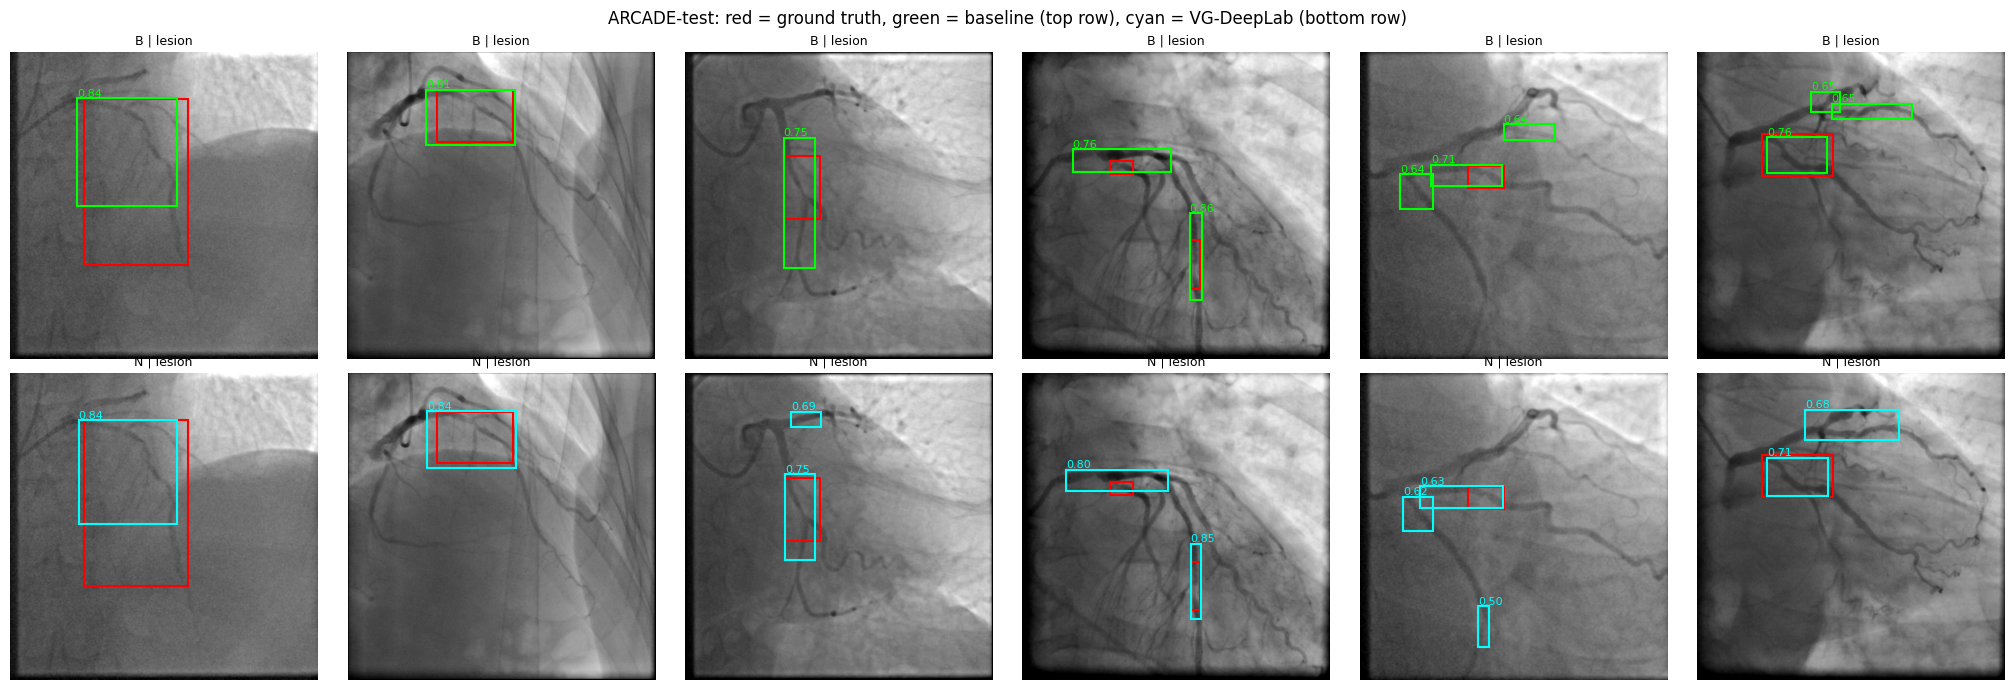

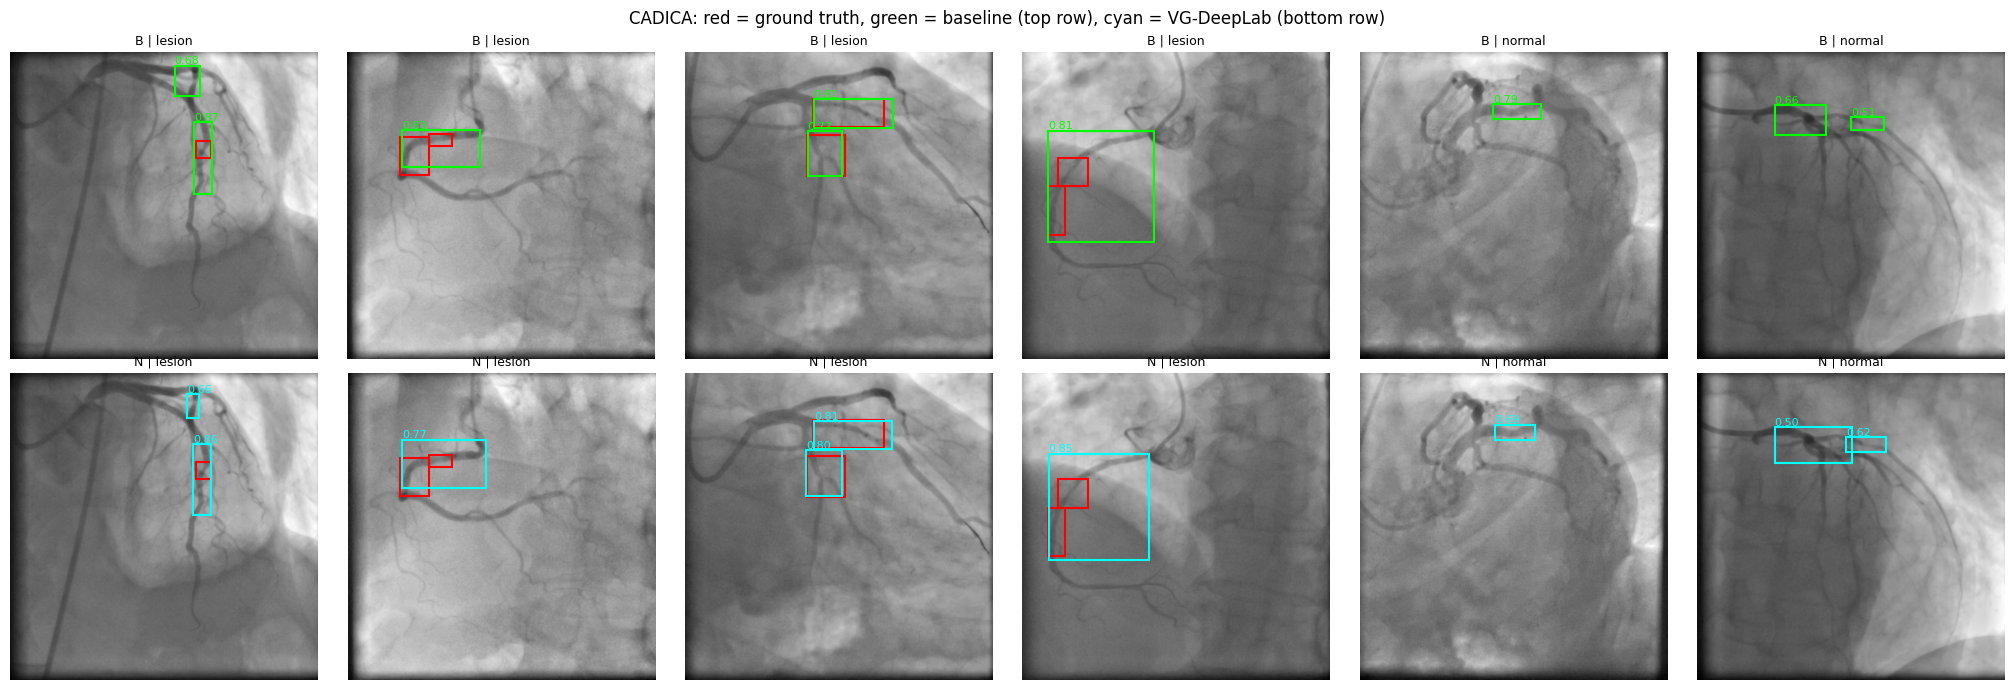

In [8]:
try:
    # ---- SS-C6: qualitative. Red = GT box, green = baseline prediction, cyan = VG-DeepLab prediction ----
    def show_frames(dn, n=6, seed=1):
        D = DATASETS[dn]; rng = np.random.default_rng(seed)
        les = [i for i, k in enumerate(D["kinds"]) if k == "lesion"]; nor = [i for i, k in enumerate(D["kinds"]) if k == "normal"]
        pick = list(rng.choice(les, min(n - (2 if nor else 0), len(les)), replace=False)) + (list(rng.choice(nor, min(2, len(nor)), replace=False)) if nor else [])
        fig, ax = plt.subplots(2, len(pick), figsize=(3.4 * len(pick), 7.0), squeeze=False)
        for c_, i in enumerate(pick):
            for r_, (k, col) in enumerate([("B", "lime"), ("N", "cyan")]):
                a = ax[r_, c_]; a.imshow(D["imgs"][i], cmap="gray"); a.axis("off")
                for b in D["boxes"][i]: a.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=1.5))
                for q in INST[(k, dn)][i]:
                    b = q["box"]; a.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=col, lw=1.5)); a.text(b[0], max(b[1] - 4, 0), f"{q['score']:.2f}", color=col, fontsize=8)
                a.set_title(f"{k} | {D['kinds'][i]}", fontsize=9)
        plt.suptitle(f"{dn}: red = ground truth, green = baseline (top row), cyan = VG-DeepLab (bottom row)"); plt.tight_layout(); plt.savefig(OUT_DIR / f"fig_qualitative_{dn}.png", dpi=110); plt.show()
    print("=== SS-C6: qualitative examples ===")
    for dn in DATASETS: show_frames(dn)
except Exception:
    traceback.print_exc(); ERRORS.append('qualitative figure'); print('!! ERROR in: qualitative figure (the notebook continues)')

# PART B - explainability
## B1. Built-in explanation: the vessel map
VG-DeepLab outputs a vessel probability map next to the stenosis map. A stenosis is a narrowing **of a vessel**, so a sensible prediction must lie on a vessel. We measure:
* do the **ground-truth lesions** of ARCADE-test lie on the predicted vessel map (there is no vessel label on these images, so this is an indirect check of the vessel map);
* do **predicted lesions** lie on it, and are **false positives** more often off-vessel than true positives (AUC of the "on-vessel fraction"; 0.5 = no information).

For the baseline `B` the vessel map is an *external* check (the baseline never saw it). For `N` it comes from the same network, so it is not independent evidence - say this in the thesis.

B on ARCADE-test: 433 predicted lesions | true positives (IoU>=0.1): 308 | false positives: 125
N on ARCADE-test: 420 predicted lesions | true positives (IoU>=0.1): 309 | false positives: 111
B on CADICA: 2774 predicted lesions | true positives (IoU>=0.1): 1230 | false positives: 1544
N on CADICA: 2904 predicted lesions | true positives (IoU>=0.1): 1258 | false positives: 1646

=== SS-E1a: do the true lesions lie on the predicted vessel map? ===
                             what   n mean share of lesion pixels on the vessel map [95% CI]  share expected by chance (vessel area / image)  lesions with >= 50% on vessel
ground-truth lesions, ARCADE-test 386                                    0.693 [0.680,0.705]                                           0.034                          0.938

=== SS-E1b: predicted lesions on / off the vessel map (AUC 0.5 = the vessel map says nothing about true vs false positives) ===
    dataset model  n TP  n FP  on-vessel share, TP  on-vessel share, FP AUC o

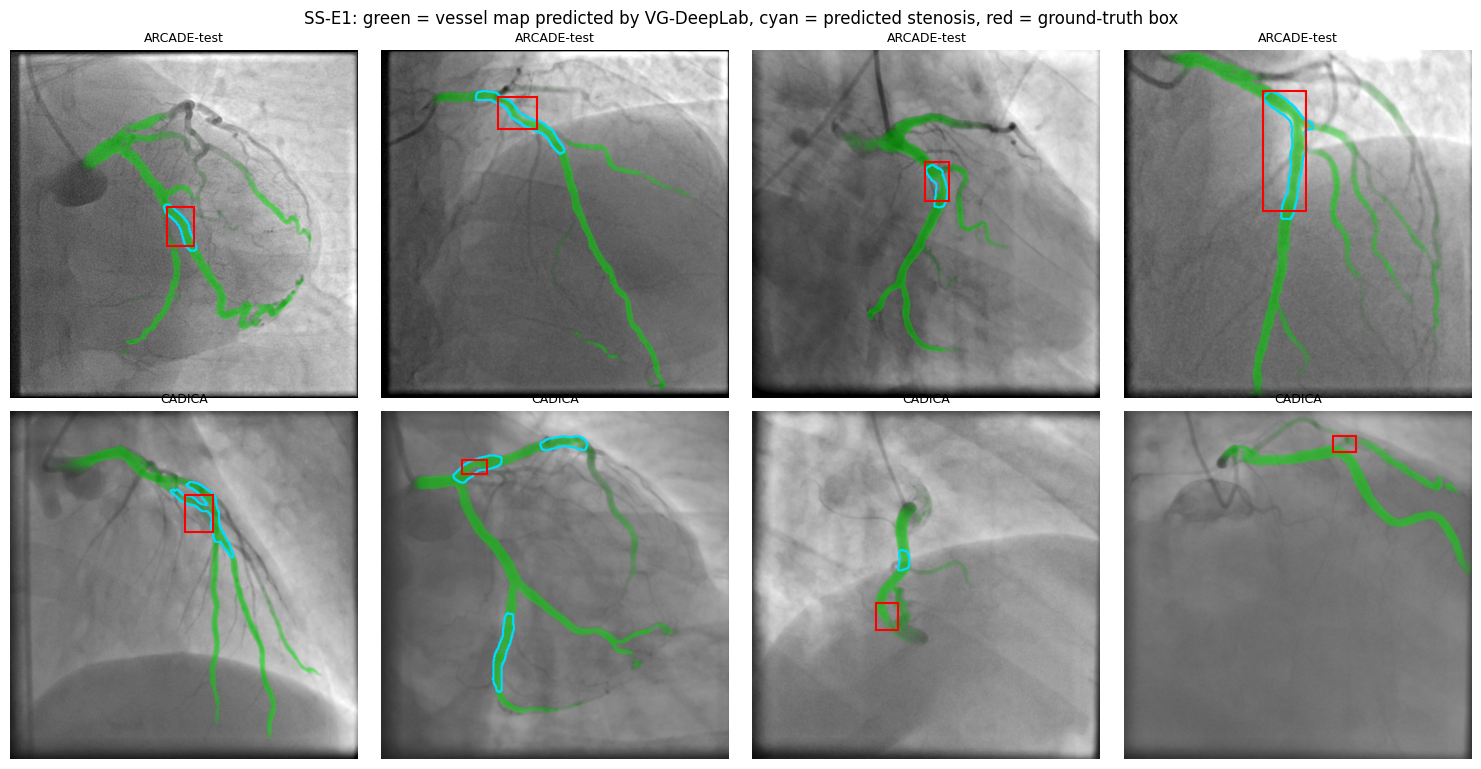

In [9]:
try:
    V_ON = 128                                             # vessel probability >= 0.5 (maps are stored as uint8)
    def cluster_ci(values, groups, fn=np.mean, seed=0):
        # bootstrap over groups (patients / images)
        values = np.asarray(values, float); groups = np.asarray(groups); ug = np.unique(groups)
        if len(values) == 0: return (np.nan, np.nan)
        idx = [np.where(groups == g)[0] for g in ug]; rng = np.random.default_rng(seed)
        b = [fn(values[np.concatenate([idx[j] for j in rng.integers(0, len(ug), len(ug))])]) for _ in range(N_BOOT)]
        return tuple(np.percentile(b, [2.5, 97.5]))
    def auc_ci(y, s, groups, seed=0):
        y, s, groups = np.asarray(y), np.asarray(s, float), np.asarray(groups)
        if len(set(y)) < 2: return np.nan, (np.nan, np.nan)
        ug = np.unique(groups); idx = [np.where(groups == g)[0] for g in ug]; rng = np.random.default_rng(seed); b = []
        for _ in range(min(N_BOOT, 500)):
            sel = np.concatenate([idx[j] for j in rng.integers(0, len(ug), len(ug))])
            if len(set(y[sel])) == 2: b.append(roc_auc_score(y[sel], s[sel]))
        return roc_auc_score(y, s), tuple(np.percentile(b, [2.5, 97.5]))

    # one row per predicted lesion: is it a true positive (box IoU >= 0.1 / >= 0.5 / centre-hit) and how much of it lies on the vessel map
    CANDDF = {}
    for (k, dn), insts in INST.items():
        D = DATASETS[dn]; rows = []
        for fi, ins in enumerate(insts):
            if not ins: continue
            pb = [i["box"] for i in ins]; t10, _ = match_frame(pb, D["boxes"][fi], "i10"); t50, _ = match_frame(pb, D["boxes"][fi], "i50"); th, _ = match_frame(pb, D["boxes"][fi], "hit")
            for rk, i in enumerate(ins):
                rows.append(dict(fi=fi, rank=rk, group=D["groups"][fi], score=i["score"], area=i["area"], y10=int(t10[rk]), y50=int(t50[rk]), yhit=int(th[rk]),
                                 on_vessel=float((VES[dn][fi][full_mask(i)] >= V_ON).mean()) if dn in VES else np.nan))
        CANDDF[(k, dn)] = pd.DataFrame(rows, columns=["fi", "rank", "group", "score", "area", "y10", "y50", "yhit", "on_vessel"])
        print(f"{k} on {dn}: {len(rows)} predicted lesions | true positives (IoU>=0.1): {int(CANDDF[(k, dn)].y10.sum())} | false positives: {int((1 - CANDDF[(k, dn)].y10).sum())}")

    rows = []
    fr, ch, grp = [], [], []
    for fi, ml in enumerate(ARC_TEST["lmasks"]):
        v = VES["ARCADE-test"][fi] >= V_ON
        for m in ml: fr.append(float(v[m].mean())); ch.append(float(v.mean())); grp.append(fi)
    lo, hi = cluster_ci(fr, grp)
    GT_VES = pd.DataFrame([{"what": "ground-truth lesions, ARCADE-test", "n": len(fr), "mean share of lesion pixels on the vessel map [95% CI]": f"{np.mean(fr):.3f} {ci(lo, hi)}",
                            "share expected by chance (vessel area / image)": round(float(np.mean(ch)), 3), "lesions with >= 50% on vessel": round(float((np.array(fr) >= 0.5).mean()), 3)}])
    print("\n=== SS-E1a: do the true lesions lie on the predicted vessel map? ==="); print(GT_VES.to_string(index=False))
    for (k, dn), df in CANDDF.items():
        if dn not in VES or not len(df): continue
        a, (alo, ahi) = auc_ci(df.y10.values, df.on_vessel.values, df.group.values); a2, (blo, bhi) = auc_ci(df.y10.values, df.score.values, df.group.values)
        rows.append({"dataset": dn, "model": k, "n TP": int(df.y10.sum()), "n FP": int((1 - df.y10).sum()), "on-vessel share, TP": round(df[df.y10 == 1].on_vessel.mean(), 3), "on-vessel share, FP": round(df[df.y10 == 0].on_vessel.mean(), 3),
                     "AUC on-vessel share (TP vs FP) [95% CI]": f"{a:.3f} {ci(alo, ahi)}", "AUC model score [95% CI]": f"{a2:.3f} {ci(blo, bhi)}"})
    TAB_VES = pd.DataFrame(rows)
    print("\n=== SS-E1b: predicted lesions on / off the vessel map (AUC 0.5 = the vessel map says nothing about true vs false positives) ==="); print(TAB_VES.to_string(index=False))
    GT_VES.to_csv(OUT_DIR / "partB_vessel_gt_lesions.csv", index=False); TAB_VES.to_csv(OUT_DIR / "partB_vessel_tp_fp.csv", index=False)

    fig, ax = plt.subplots(len(DATASETS), 4, figsize=(15, 3.9 * len(DATASETS)), squeeze=False)
    for r_, (dn, D) in enumerate(DATASETS.items()):
        les = [i for i, k_ in enumerate(D["kinds"]) if k_ == "lesion"]
        for c_, i in enumerate(np.array(les)[np.linspace(0, len(les) - 1, 4).astype(int)]):
            o = cv2.cvtColor(D["imgs"][i], cv2.COLOR_GRAY2RGB).astype(np.float32); v = VES[dn][i].astype(np.float32)[..., None] / 255
            o = o * (1 - 0.45 * v) + 0.45 * v * np.array([0, 255, 0], np.float32); pm = paint(INST[("N", dn)][i]).astype(np.uint8)
            o = o.clip(0, 255).astype(np.uint8); cv2.drawContours(o, cv2.findContours(pm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0], -1, (0, 220, 255), 2)
            ax[r_, c_].imshow(o); ax[r_, c_].axis("off"); ax[r_, c_].set_title(dn, fontsize=9)
            for b in D["boxes"][i]: ax[r_, c_].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=1.5))
    plt.suptitle("SS-E1: green = vessel map predicted by VG-DeepLab, cyan = predicted stenosis, red = ground-truth box"); plt.tight_layout(); plt.savefig(OUT_DIR / "fig_vessel_map.png", dpi=110); plt.show()
except Exception:
    traceback.print_exc(); ERRORS.append('B1 vessel map'); print('!! ERROR in: B1 vessel map (the notebook continues)')

## B2. Counterfactual test: does the model really use the vessel map?
The refinement head of VG-DeepLab receives three inputs: the image, the coarse stenosis probability and the vessel probability. We change **only the vessel input** and look at the output:
* `vessel blank` - the vessel map is replaced by "no vessel anywhere";
* `vessel swapped` - the vessel map of a *different* image is given;
* `refinement off` - the coarse output before refinement (how much the whole refinement head changes).

If the Dice does not move when the vessel map is blanked, the model does **not** rely on it, and the vessel map must not be presented as "the reason" for the prediction. (No test-time augmentation here, so "normal" can differ slightly from the main result.)

In [10]:
try:
    VARIANTS = ["normal", "vessel blank", "vessel swapped", "refinement off"]
    @torch.no_grad()
    def variant_probs(models, imgs, bs=8):
        out = {v: [] for v in VARIANTS}
        for st in tqdm(range(0, len(imgs), bs), mininterval=20, desc="counterfactual"):
            x = torch.from_numpy(np.stack(imgs[st:st + bs])).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(DEVICE); acc = {v: 0.0 for v in VARIANTS}
            for m in models:
                with autocast("cuda", enabled=USE_CUDA): o = m.net((x - m.mean) / m.std)
                s = o[:, :1].float(); v = torch.sigmoid(o[:, 1:2].float())
                def ref(vin): return torch.sigmoid(s + m.ref(torch.cat([x[:, :1] * 2 - 1, torch.sigmoid(s) * 2 - 1, vin * 2 - 1], 1)))
                acc["normal"] = acc["normal"] + ref(v); acc["vessel blank"] = acc["vessel blank"] + ref(torch.zeros_like(v))
                acc["vessel swapped"] = acc["vessel swapped"] + ref(torch.roll(v, 1, 0) if len(x) > 1 else torch.flip(v, dims=[2, 3])); acc["refinement off"] = acc["refinement off"] + torch.sigmoid(s)
            for v_ in VARIANTS: out[v_].append((acc[v_] / len(models))[:, 0].cpu().numpy().astype(np.float32))
        return {v_: np.concatenate(a) for v_, a in out.items()}

    VP = variant_probs(MODELS["N"], ARC_TEST["imgs"]); gt = ARC_TEST["masks"] > 0; n_img = len(gt)
    vd = {v_: np.array([dice_img(paint(extract_instances(p, FROZEN_OPS["N"])), g) for p, g in zip(VP[v_], gt)]) for v_ in VARIANTS}
    rows = []; rng = np.random.default_rng(0); BI = [rng.integers(0, n_img, n_img) for _ in range(N_BOOT)]; act = VP["normal"] > 0.1
    for v_ in VARIANTS:
        d = vd[v_] - vd["normal"]; bb = [d[i].mean() for i in BI]; lo, hi = np.percentile(bb, [2.5, 97.5])
        rows.append({"input to the refinement head": v_, "Dice/img": round(float(vd[v_].mean()), 4), "change vs normal": round(float(d.mean()), 4), "95% CI": "-" if v_ == "normal" else f"[{lo:+.4f}, {hi:+.4f}]",
                     "CI excludes 0": "-" if v_ == "normal" else ("YES" if (lo > 0 or hi < 0) else "no"), "mean |change| of the probability where the model is active": round(float(np.abs(VP[v_] - VP["normal"])[act].mean()), 4)})
    TAB_CF = pd.DataFrame(rows)
    print("=== SS-E2: counterfactual test on ARCADE-test (VG-DeepLab ensemble, no TTA) ==="); print(TAB_CF.to_string(index=False)); TAB_CF.to_csv(OUT_DIR / "partB_counterfactual_vessel_input.csv", index=False)
    r_blank = TAB_CF.iloc[1]
    print("\n--- what the data supports ---")
    print("Blanking the vessel map", "changes the Dice reliably (the refinement head uses the vessel map)." if r_blank["CI excludes 0"] == "YES" else
          "does NOT change the Dice reliably: the refinement head makes little use of the vessel map. The vessel head then helps (if at all) through the shared features during training, not as an input at test time.")
    del VP
except Exception:
    traceback.print_exc(); ERRORS.append('B2 counterfactual'); print('!! ERROR in: B2 counterfactual (the notebook continues)')

counterfactual:   0%|          | 0/38 [00:00<?, ?it/s]

=== SS-E2: counterfactual test on ARCADE-test (VG-DeepLab ensemble, no TTA) ===
input to the refinement head  Dice/img  change vs normal             95% CI CI excludes 0  mean |change| of the probability where the model is active
                      normal    0.6312            0.0000                  -             -                                                      0.0000
                vessel blank    0.6367            0.0055 [+0.0008, +0.0107]           YES                                                      0.0794
              vessel swapped    0.6365            0.0054 [+0.0008, +0.0102]           YES                                                      0.0721
              refinement off    0.6240           -0.0072 [-0.0112, -0.0035]           YES                                                      0.0240

--- what the data supports ---
Blanking the vessel map changes the Dice reliably (the refinement head uses the vessel map).


## B3. Seg-Grad-CAM for the ensemble: where does the evidence come from?
For every predicted lesion the target is the mean stenosis logit inside that lesion; the CAM is computed at the DeepLabV3+ decoder output for each of the 5 fold models and averaged. **Localisation** is measured on true-positive detections: *pointing game* (is the CAM maximum inside the ground-truth box / mask?) and *energy lift* (share of CAM energy inside the GT box divided by the box's share of the image; 1 = no better than uniform). On ARCADE **all** true positives of the 300 test images are used.

Honest note: the CAM target is the predicted lesion itself, so a high pointing-game score on true positives is partly expected. That is why the deletion and randomisation tests follow.

CAM B ARCADE-test:   0%|          | 0/280 [00:00<?, ?it/s]

CAM N ARCADE-test:   0%|          | 0/278 [00:00<?, ?it/s]

CAM B CADICA:   0%|          | 0/294 [00:00<?, ?it/s]

CAM N CADICA:   0%|          | 0/291 [00:00<?, ?it/s]

=== SS-E3: CAM localisation on true-positive detections (earlier single model, 150 detections: pointing game 0.81 ARCADE / 0.57 CADICA) ===
    dataset model  n TP pointing game (box) [95% CI]  chance energy lift [95% CI] pointing game (GT mask) [95% CI] chance (mask)
ARCADE-test     B   308          0.831 [0.790,0.870]   0.032     34.9 [31.9,38.3]              0.951 [0.925,0.975]        0.0104
ARCADE-test     N   309          0.822 [0.782,0.860]   0.032     35.4 [32.0,38.6]              0.945 [0.919,0.968]        0.0102
     CADICA     B   300          0.663 [0.588,0.739]   0.010     65.3 [54.5,78.9]                                -             -
     CADICA     N   300          0.670 [0.601,0.744]   0.010     64.6 [54.5,76.5]                                -             -

=== SS-E4: Seg-Grad-CAM examples ===


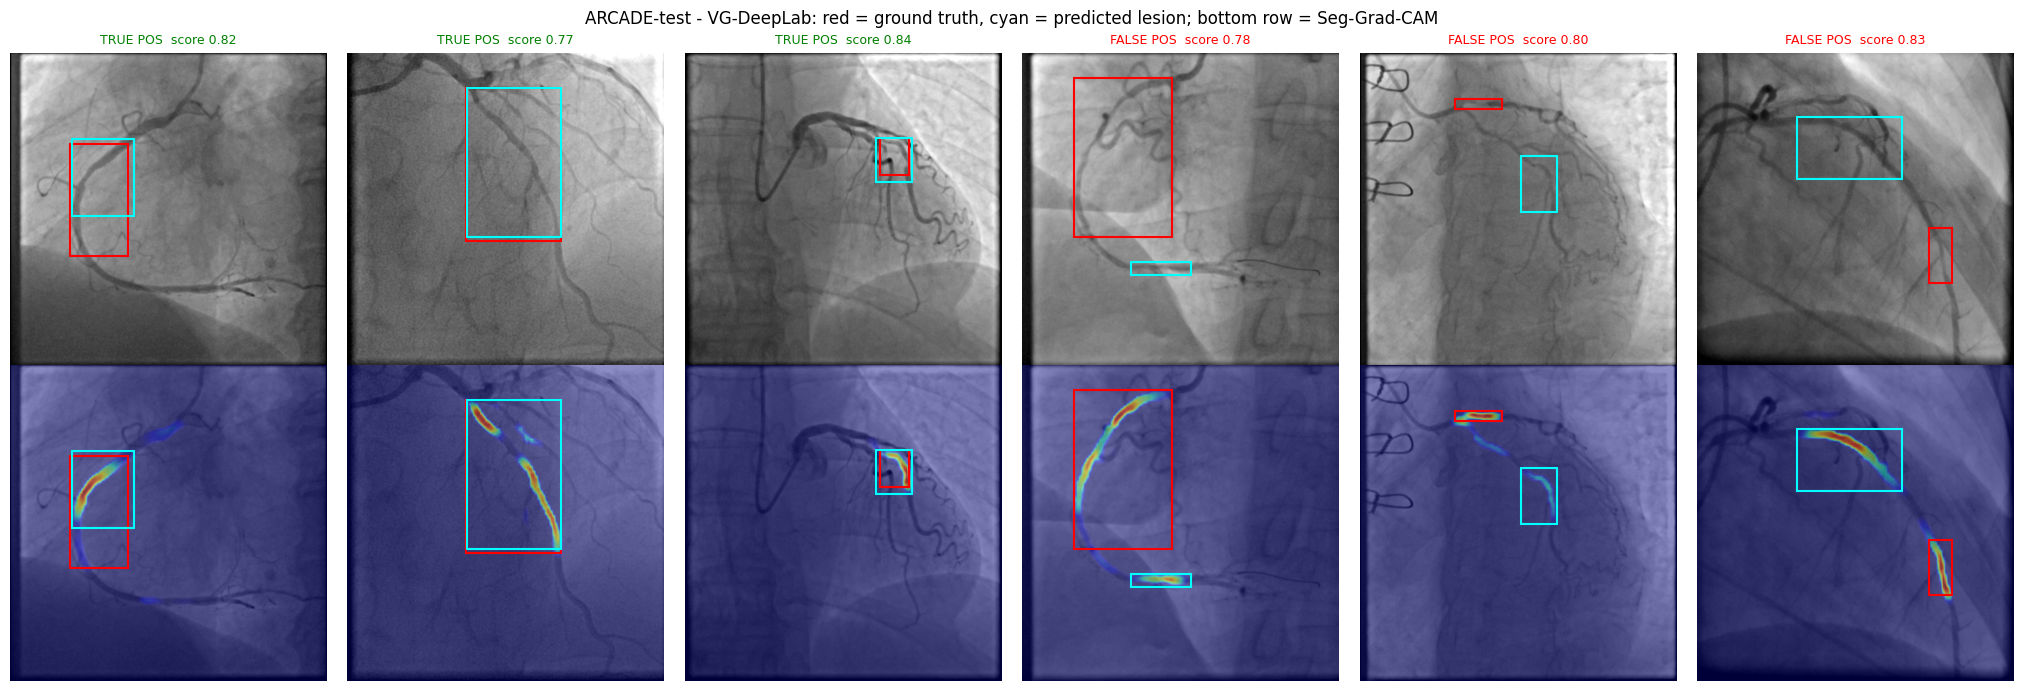

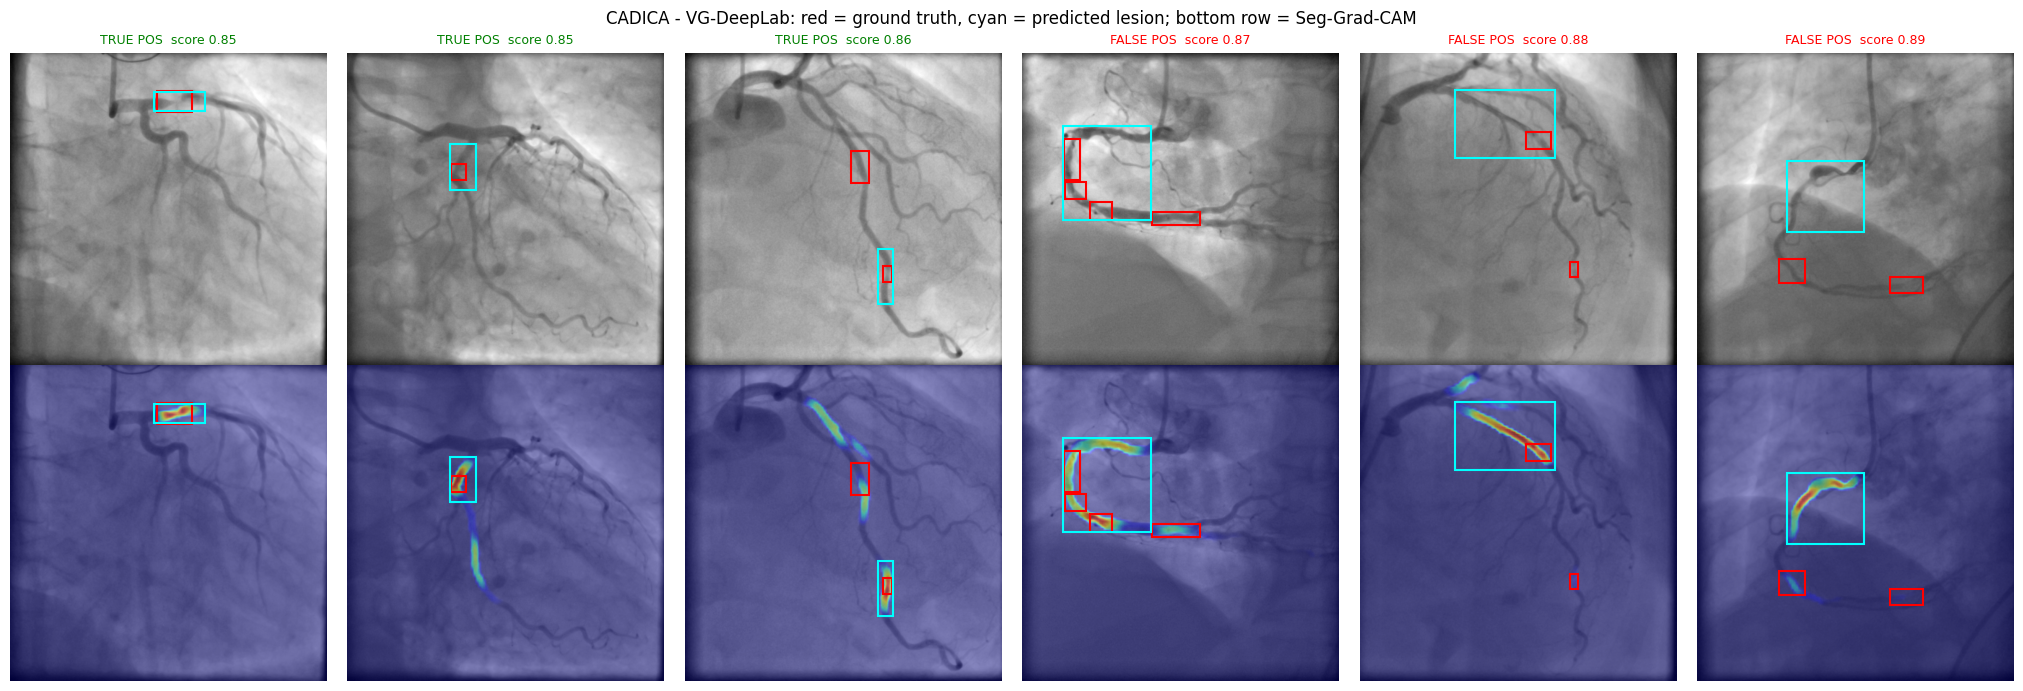

In [11]:
try:
    class EnsCAM:
        # Seg-Grad-CAM (Vinogradova et al. 2020) averaged over the fold models
        def __init__(self, models):
            self.models = models; self.acts = [None] * len(models); self.hooks = [m.net.decoder.register_forward_hook(self._mk(i)) for i, m in enumerate(models)]
        def _mk(self, i):
            def f(mod, inp, out): self.acts[i] = out[-1] if isinstance(out, (list, tuple)) else out
            return f
        def close(self):
            for h in self.hooks: h.remove()
        def run(self, gray, regions):
            x = torch.from_numpy(np.ascontiguousarray(gray)).float().div(255)[None, None].repeat(1, 3, 1, 1).to(DEVICE)
            regs = [torch.from_numpy(r.astype(np.float32)).to(DEVICE) for r in regions]; cams = [0.0] * len(regs)
            with torch.enable_grad():
                for i, m in enumerate(self.models):
                    xi = x.clone().requires_grad_(True); logit = m.parts(xi, detach=False)[0].float(); act = self.acts[i]
                    for j, r in enumerate(regs):
                        score = (logit[0, 0] * r).sum() / (r.sum() + 1e-6)
                        g = torch.autograd.grad(score, act, retain_graph=(j < len(regs) - 1))[0]
                        cam = F.relu((g.mean((2, 3), keepdim=True) * act).sum(1, keepdim=True))
                        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]; cam = cam - cam.min(); cam = cam / (cam.max() + 1e-8)
                        cams[j] = cams[j] + cam.detach()
            return [(c / (c.max() + 1e-8)).cpu().numpy() for c in cams]

    def localisation(k, dn, n_max=None):
        D = DATASETS[dn]; tp = CANDDF[(k, dn)]; tp = tp[tp.y10 == 1]
        if n_max and len(tp) > n_max: tp = tp.sample(n_max, random_state=0)
        eng = EnsCAM(MODELS[k]); rows = []
        for fi, sub in tqdm(list(tp.groupby("fi")), mininterval=20, desc=f"CAM {k} {dn}"):
            fi = int(fi); inss = [INST[(k, dn)][fi][int(r)] for r in sub["rank"]]; cams = eng.run(D["imgs"][fi], [full_mask(i) for i in inss])
            for ins, cam in zip(inss, cams):
                gb = max(D["boxes"][fi], key=lambda b: box_iou(ins["box"], b)); x0, y0, x1, y1 = [int(round(v)) for v in gb]
                x0, y0, x1, y1 = max(x0, 0), max(y0, 0), min(x1, IMG_SIZE), min(y1, IMG_SIZE)
                if x1 <= x0 or y1 <= y0: continue
                am = np.unravel_index(np.argmax(cam), cam.shape); frac = (x1 - x0) * (y1 - y0) / IMG_SIZE ** 2
                row = dict(group=D["groups"][fi], pg=float(y0 <= am[0] < y1 and x0 <= am[1] < x1), chance=frac, lift=float(cam[y0:y1, x0:x1].sum() / (cam.sum() + 1e-8)) / frac)
                if D["masks"] is not None: gm = D["masks"][fi] > 0; row.update(pg_mask=float(gm[am]), chance_mask=float(gm.mean()))
                rows.append(row)
        eng.close(); return pd.DataFrame(rows)

    rows, LOCRAW = [], {}
    for dn in DATASETS:
        for k in SPECS:
            L = localisation(k, dn, None if dn == "ARCADE-test" else N_LOC_CAD); LOCRAW[(k, dn)] = L
            if not len(L): continue
            r = {"dataset": dn, "model": k, "n TP": len(L), "pointing game (box) [95% CI]": f"{L.pg.mean():.3f} {ci(*cluster_ci(L.pg, L.group))}", "chance": round(L.chance.mean(), 3),
                 "energy lift [95% CI]": f"{L.lift.mean():.1f} [{cluster_ci(L.lift, L.group)[0]:.1f},{cluster_ci(L.lift, L.group)[1]:.1f}]"}
            if "pg_mask" in L: r.update({"pointing game (GT mask) [95% CI]": f"{L.pg_mask.mean():.3f} {ci(*cluster_ci(L.pg_mask, L.group))}", "chance (mask)": round(L.chance_mask.mean(), 4)})
            rows.append(r)
    LOC = pd.DataFrame(rows)
    print("=== SS-E3: CAM localisation on true-positive detections (earlier single model, 150 detections: pointing game 0.81 ARCADE / 0.57 CADICA) ==="); print(LOC.fillna("-").to_string(index=False))
    LOC.to_csv(OUT_DIR / "partB_cam_localisation.csv", index=False)

    def show_cam_examples(dn, k="N", n_each=3, seed=3):
        D = DATASETS[dn]; df = CANDDF[(k, dn)]; tp, fp = df[df.y10 == 1], df[df.y10 == 0].sort_values("score", ascending=False).head(40)
        pick = list(tp.sample(min(n_each, len(tp)), random_state=seed).itertuples()) + list(fp.sample(min(n_each, len(fp)), random_state=seed).itertuples())
        if not pick: return
        eng = EnsCAM(MODELS[k]); fig, ax = plt.subplots(2, len(pick), figsize=(3.4 * len(pick), 7.0), squeeze=False)
        for c_, r in enumerate(pick):
            ins = INST[(k, dn)][int(r.fi)][int(r.rank)]; g = D["imgs"][int(r.fi)]; cam = eng.run(g, [full_mask(ins)])[0]
            for rr in range(2):
                ax[rr, c_].imshow(g, cmap="gray"); ax[rr, c_].axis("off"); b = ins["box"]
                for gb in D["boxes"][int(r.fi)]: ax[rr, c_].add_patch(plt.Rectangle((gb[0], gb[1]), gb[2] - gb[0], gb[3] - gb[1], fill=False, ec="red", lw=1.5))
                ax[rr, c_].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="cyan", lw=1.5))
            ax[1, c_].imshow(cam, cmap="jet", alpha=0.45); ax[0, c_].set_title(("TRUE POS" if r.y10 else "FALSE POS") + f"  score {r.score:.2f}", color="green" if r.y10 else "red", fontsize=9)
        eng.close(); plt.suptitle(f"{dn} - VG-DeepLab: red = ground truth, cyan = predicted lesion; bottom row = Seg-Grad-CAM"); plt.tight_layout(); plt.savefig(OUT_DIR / f"fig_cam_examples_{dn}.png", dpi=110); plt.show()
    print("\n=== SS-E4: Seg-Grad-CAM examples ===")
    for dn in DATASETS: show_cam_examples(dn)
except Exception:
    traceback.print_exc(); ERRORS.append('B3 Grad-CAM localisation'); print('!! ERROR in: B3 Grad-CAM localisation (the notebook continues)')

## B4. Faithfulness (deletion test) and B5. sanity (weight randomisation) - VG-DeepLab
* **Deletion:** blur the pixels that the CAM marks as most important (1 %, 2 %, 5 %, 10 % of the image) and measure how much of the lesion probability survives, compared with blurring the same number of *random* pixels. `cam_ctx` / `rand_ctx` do the same but are **not allowed to touch the lesion and a margin around it**: this tests whether the model relies on the surrounding context.
* **Sanity:** randomise the weights (output head → + decoder → everything) and check that the CAM changes. A CAM that stays the same is not explaining the trained model (Adebayo et al. 2018).

deletion ARCADE-test TP:   0%|          | 0/120 [00:00<?, ?it/s]

deletion ARCADE-test FP:   0%|          | 0/111 [00:00<?, ?it/s]

deletion CADICA TP:   0%|          | 0/80 [00:00<?, ?it/s]

deletion CADICA FP:   0%|          | 0/80 [00:00<?, ?it/s]

=== SS-E5: deletion test, VG-DeepLab (retained = lesion probability after deletion / before; 'faithful' = the CAM pixels matter more than random pixels, CI above 0; 'too few' = fewer than 10 detections) ===
    dataset detections   n  % deleted  retained: cam  retained: random  random - cam [95% CI] faithful
ARCADE-test         TP 120        1.0          0.463             0.989 +0.526 [+0.469,+0.579]      YES
ARCADE-test         TP 120        2.0          0.247             0.969 +0.722 [+0.680,+0.764]      YES
ARCADE-test         TP 120        5.0          0.147             0.944 +0.797 [+0.758,+0.834]      YES
ARCADE-test         TP 120       10.0          0.147             0.906 +0.759 [+0.719,+0.796]      YES
ARCADE-test         FP 111        1.0          0.732             0.960 +0.228 [+0.128,+0.320]      YES
ARCADE-test         FP 111        2.0          0.424             0.926 +0.502 [+0.429,+0.580]      YES
ARCADE-test         FP 111        5.0          0.192             0.866 +

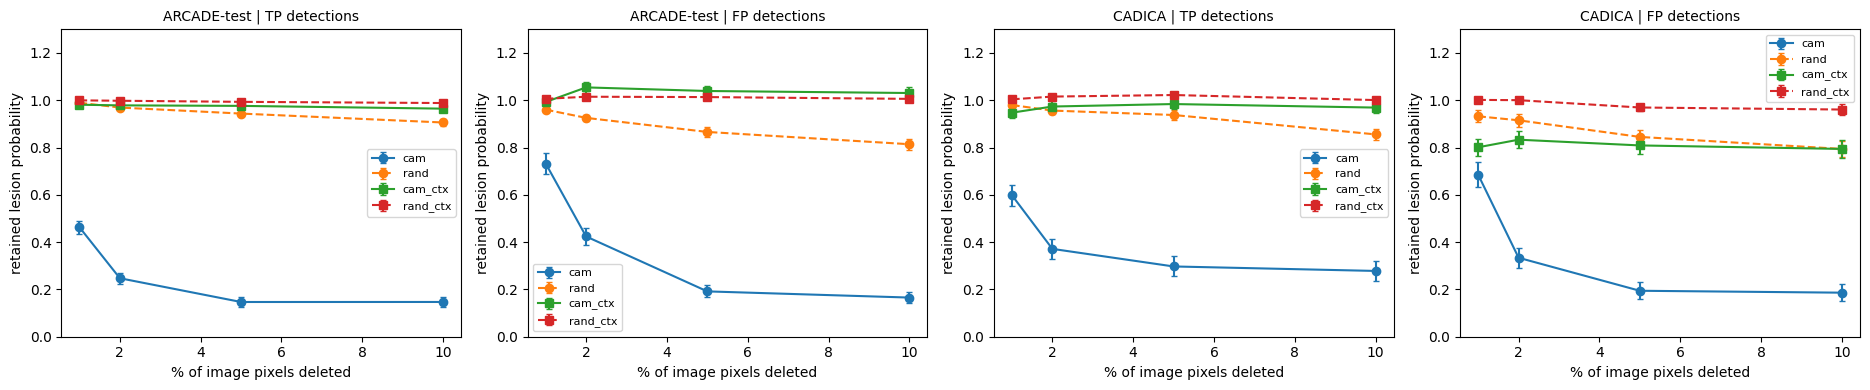

In [12]:
try:
    @torch.no_grad()
    def ens_prob_plain(models, imgs, bs=16):
        out = []
        for st in range(0, len(imgs), bs):
            x = torch.from_numpy(np.stack(imgs[st:st + bs])).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(DEVICE); acc = 0.0
            for m in models:
                with autocast("cuda", enabled=USE_CUDA): s2 = m(x)[0]
                acc = acc + torch.sigmoid(s2.float())
            out.append((acc / len(models))[:, 0].cpu().numpy())
        return np.concatenate(out)

    def pick_rows(k, dn, kind, n, seed=0):
        d = CANDDF[(k, dn)]; sub = d[d.y10 == (1 if kind == "TP" else 0)]; return sub.sample(min(n, len(sub)), random_state=seed)

    MODES = ["cam", "rand", "cam_ctx", "rand_ctx"]
    def deletion(k, dn, kind, n):
        D = DATASETS[dn]; eng = EnsCAM(MODELS[k]); rng = np.random.default_rng(0); out = []
        e = max(3, int(round(51 * IMG_SIZE / 512)) | 1); ell = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (e, e))
        for r in tqdm(list(pick_rows(k, dn, kind, n).itertuples()), mininterval=20, desc=f"deletion {dn} {kind}"):
            ins = INST[(k, dn)][int(r.fi)][int(r.rank)]; g = D["imgs"][int(r.fi)]; reg = full_mask(ins); cam = eng.run(g, [reg])[0]; blur = cv2.GaussianBlur(g, (0, 0), 20 * IMG_SIZE / 512)
            excl = cv2.dilate(reg.astype(np.uint8), ell).astype(bool); variants = [(0.0, "base", g)]
            for frac in DEL_FRACS:
                kpx = int(frac * IMG_SIZE ** 2)
                for mode in MODES:
                    smap = (cam if mode.startswith("cam") else rng.random(cam.shape)) + 1e-6 * rng.random(cam.shape)
                    if mode.endswith("ctx"): smap[excl] = -1
                    idx = np.argpartition(-smap.ravel(), kpx)[:kpx]; M = np.zeros(IMG_SIZE * IMG_SIZE, bool); M[idx] = True
                    variants.append((frac, mode, np.where(M.reshape(IMG_SIZE, IMG_SIZE), blur, g)))
            probs = ens_prob_plain(MODELS[k], [v[2] for v in variants]); base = max(float(probs[0][reg].mean()), 1e-6)
            for (frac, mode, _), p in zip(variants[1:], probs[1:]):
                out.append(dict(dataset=dn, kind=kind, group=D["groups"][int(r.fi)], inst=f"{r.fi}_{r.rank}", frac=frac, mode=mode, retained=float(np.clip(p[reg].mean() / base, 0, 1.5))))
        eng.close(); return out

    DEL = pd.DataFrame(sum([deletion("N", dn, kind, N_DEL[dn]) for dn in DATASETS for kind in ["TP", "FP"]], []))
    DEL.to_csv(OUT_DIR / "partB_deletion_raw.csv", index=False)
    rows = []
    for (dn, kind), sub in DEL.groupby(["dataset", "kind"], sort=False):
        for frac in DEL_FRACS:
            w = sub[sub.frac == frac].pivot(index="inst", columns="mode", values="retained"); grp = sub[sub.frac == frac].drop_duplicates("inst").set_index("inst").loc[w.index, "group"].values
            d1 = (w["rand"] - w["cam"]).values; d2 = (w["rand_ctx"] - w["cam_ctx"]).values; l1, h1 = cluster_ci(d1, grp); l2, h2 = cluster_ci(d2, grp)
            rows.append({"dataset": dn, "detections": kind, "n": len(w), "% deleted": 100 * frac, "retained: cam": round(w["cam"].mean(), 3), "retained: random": round(w["rand"].mean(), 3),
                         "random - cam [95% CI]": f"{d1.mean():+.3f} [{l1:+.3f},{h1:+.3f}]", "faithful": "too few" if len(w) < 10 else ("YES" if l1 > 0 else "no"),
                         "retained: cam_ctx": round(w["cam_ctx"].mean(), 3), "retained: rand_ctx": round(w["rand_ctx"].mean(), 3), "rand_ctx - cam_ctx [95% CI]": f"{d2.mean():+.3f} [{l2:+.3f},{h2:+.3f}]"})
    TAB_DEL = pd.DataFrame(rows)
    print("=== SS-E5: deletion test, VG-DeepLab (retained = lesion probability after deletion / before; 'faithful' = the CAM pixels matter more than random pixels, CI above 0; 'too few' = fewer than 10 detections) ===")
    print(TAB_DEL.iloc[:, :8].to_string(index=False)); print("\ncontext only (the lesion and a margin around it are never deleted):"); print(TAB_DEL.iloc[:, [0, 1, 3, 8, 9, 10]].to_string(index=False))
    TAB_DEL.to_csv(OUT_DIR / "partB_deletion_summary.csv", index=False)
    agg = DEL.groupby(["dataset", "kind", "mode", "frac"]).retained.agg(["mean", "sem"]).reset_index(); combos = [(d, k_) for d in DATASETS for k_ in ["TP", "FP"]]
    fig, ax = plt.subplots(1, len(combos), figsize=(4.7 * len(combos), 4), squeeze=False)
    for a, (dn, k_) in zip(ax[0], combos):
        for mode, st_ in [("cam", "-o"), ("rand", "--o"), ("cam_ctx", "-s"), ("rand_ctx", "--s")]:
            s = agg[(agg.dataset == dn) & (agg.kind == k_) & (agg["mode"] == mode)]; a.errorbar(s.frac * 100, s["mean"], yerr=s["sem"].fillna(0), fmt=st_, label=mode, capsize=2)
        a.set_title(f"{dn} | {k_} detections", fontsize=10); a.set_xlabel("% of image pixels deleted"); a.set_ylabel("retained lesion probability"); a.set_ylim(0, 1.3); a.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(OUT_DIR / "fig_deletion.png", dpi=110); plt.show()
except Exception:
    traceback.print_exc(); ERRORS.append('B4 deletion'); print('!! ERROR in: B4 deletion (the notebook continues)')

In [13]:
try:
    def sanity(k, dn, n):
        D = DATASETS[dn]; rows_ = pick_rows(k, dn, "TP", n); items = [(D["imgs"][int(r.fi)], full_mask(INST[(k, dn)][int(r.fi)][int(r.rank)]), D["groups"][int(r.fi)]) for r in rows_.itertuples()]
        if not items: return None
        s64 = max(16, IMG_SIZE // 8)
        def cams_of(models):
            e = EnsCAM(models); out = [cv2.resize(e.run(g, [reg])[0], (s64, s64), interpolation=cv2.INTER_AREA).ravel() for g, reg, _ in items]; e.close(); return out
        def rand_copies(scope):
            torch.manual_seed(SEED); out = []
            for m in MODELS[k]:
                mc = copy.deepcopy(m); head = [mc.net.segmentation_head] + ([mc.ref] if mc.refine else [])
                for sub in {"head": head, "head+decoder": head + [mc.net.decoder], "all": [mc]}[scope]:
                    for mod in sub.modules():
                        if hasattr(mod, "reset_parameters"): mod.reset_parameters()
                out.append(mc.eval())
            return out
        ref = cams_of(MODELS[k]); res = {"dataset": dn, "n": len(items)}; grp = [g for _, _, g in items]
        for scope in ["head", "head+decoder", "all"]:
            mcs = rand_copies(scope); cc = cams_of(mcs); del mcs; torch.cuda.empty_cache(); rho = []
            for a, b in zip(ref, cc):
                r_ = spearmanr(a, b)[0] if (a.std() > 0 and b.std() > 0) else 0.0; rho.append(0.0 if (r_ is None or np.isnan(r_)) else float(r_))
            lo, hi = cluster_ci(rho, grp); res[f"randomised: {scope} [95% CI]"] = f"{np.mean(rho):.3f} {ci(lo, hi)}"
        return res
    SAN = pd.DataFrame([r for r in [sanity("N", dn, N_SANITY) for dn in DATASETS] if r])
    print("=== SS-E6: sanity check, VG-DeepLab - Spearman correlation between the real CAM and the CAM after randomising weights (should fall toward 0) ===")
    print(SAN.to_string(index=False)); SAN.to_csv(OUT_DIR / "partB_sanity.csv", index=False)
except Exception:
    traceback.print_exc(); ERRORS.append('B5 sanity'); print('!! ERROR in: B5 sanity (the notebook continues)')

=== SS-E6: sanity check, VG-DeepLab - Spearman correlation between the real CAM and the CAM after randomising weights (should fall toward 0) ===
    dataset  n randomised: head [95% CI] randomised: head+decoder [95% CI] randomised: all [95% CI]
ARCADE-test 40       0.275 [0.260,0.289]               0.051 [0.027,0.074]   -0.069 [-0.098,-0.039]
     CADICA 40       0.247 [0.218,0.278]               0.033 [0.011,0.059]      0.044 [0.018,0.070]


In [14]:
# ---- final status ----
for k, df in CANDDF.items(): df.to_csv(OUT_DIR / f"detections_{k[0]}_{k[1]}.csv", index=False)
ZIP_BASE = str(BASE / ("results_cadica_explain_smoke" if SMOKE_TEST else "results_cadica_explain")); shutil.make_archive(ZIP_BASE, "zip", OUT_DIR)
print("Saved tables and figures to", OUT_DIR, "| zip:", ZIP_BASE + ".zip")
if ERRORS:
    print("!" * 100); print("FINISHED WITH PROBLEMS in:", ERRORS); print("The other parts are complete and saved. Send Claude the zip and the error text printed above."); print("!" * 100)
else: print("ALL DONE - no errors. Send Claude the zip 'results_cadica_explain.zip' from the Output panel (and the figures SS-C6, SS-E1, SS-E4, SS-E5 if you can).")
if SMOKE_TEST: print("SMOKE TEST: the numbers mean nothing. Set SMOKE_TEST = False for the real run.")

Saved tables and figures to /kaggle/working/outputs_cadica_explain | zip: /kaggle/working/results_cadica_explain.zip
ALL DONE - no errors. Send Claude the zip 'results_cadica_explain.zip' from the Output panel (and the figures SS-C6, SS-E1, SS-E4, SS-E5 if you can).


## How to use this in the thesis (so nothing is over-claimed)
* **Cross-dataset (SS-C2 to SS-C5).** Report the drop for both models. Say that VG-DeepLab is more robust **only if** SS-C4 shows "YES" on CADICA. CADICA has box labels only and 29 % of them are very mild (`p0_20`) lesions that ARCADE does not annotate in the same way, so part of the drop is a label-definition difference, not only an image difference.
* **Vessel map (SS-E1, SS-E2).** It is a built-in, human-readable intermediate output. You may call it an explanation of *where the model looks for vessels*. Call it *the reason for the prediction* only if SS-E2 shows that blanking it changes the output.
* **Grad-CAM (SS-E3 to SS-E6).** Supportable claims, each only if its number says so: localisation above chance; deletion `random - cam` above 0 (faithful); correlation near 0 after randomisation (sanity). No clinician looked at the maps, so do not claim clinical usefulness.
* The operating points were frozen before this notebook; nothing was tuned on CADICA or on the ARCADE test set here.